In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

if torch.cuda.is_available():
    print("GPU Available:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("GPU not available. Using CPU.")

print("GPU Ready:", torch.cuda.is_available())

PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
GPU Available: Tesla T4
CUDA version: 13.0
GPU Ready: True


In [ ]:
import os

DATA_DIR = "/content/drive/MyDrive/kneeai"

print("Dataset exists:", os.path.exists(DATA_DIR))
print("Dataset path:", DATA_DIR)

for folder in ["0", "1", "2", "3"]:
    path = os.path.join(DATA_DIR, folder)

    if os.path.exists(path):
        files = [f for f in os.listdir(path)
                 if f.lower().endswith(".jpg")]
        print(f"KL Grade {folder}: {len(files)} images")
    else:
        print(f"KL Grade {folder}: MISSING")

Dataset exists: True
Dataset path: /content/drive/MyDrive/kneeai
KL Grade 0: 3085 images
KL Grade 1: 1416 images
KL Grade 2: 2062 images
KL Grade 3: 1265 images


In [ ]:
from pathlib import Path

root = Path(DATA_DIR)

for grade in range(4):
    images = list((root / str(grade)).glob("*.jpg"))

    print(f"\nGrade {grade}")
    print("Images:", len(images))
    print("Sample:", images[:3])


Grade 0
Images: 3085
Sample: [PosixPath('/content/drive/MyDrive/kneeai/0/Image_5722.jpg'), PosixPath('/content/drive/MyDrive/kneeai/0/Image_5725.jpg'), PosixPath('/content/drive/MyDrive/kneeai/0/Image_5727.jpg')]

Grade 1
Images: 1416
Sample: [PosixPath('/content/drive/MyDrive/kneeai/1/Image_3058.jpg'), PosixPath('/content/drive/MyDrive/kneeai/1/Image_3063.jpg'), PosixPath('/content/drive/MyDrive/kneeai/1/Image_3061.jpg')]

Grade 2
Images: 2062
Sample: [PosixPath('/content/drive/MyDrive/kneeai/2/Image_4547.jpg'), PosixPath('/content/drive/MyDrive/kneeai/2/Image_4548.jpg'), PosixPath('/content/drive/MyDrive/kneeai/2/Image_4552.jpg')]

Grade 3
Images: 1265
Sample: [PosixPath('/content/drive/MyDrive/kneeai/3/Image_2513.jpg'), PosixPath('/content/drive/MyDrive/kneeai/3/Image_2528.jpg'), PosixPath('/content/drive/MyDrive/kneeai/3/Image_253.jpg')]


In [ ]:
import torch
import torchvision
import numpy as np
import pandas as pd
import sklearn
import PIL
import matplotlib

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nCUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1

CUDA Available: True
GPU: Tesla T4


In [ ]:
from PIL import Image
import os

valid = 0
invalid = []

for grade in range(4):
    folder = os.path.join(DATA_DIR, str(grade))

    for filename in os.listdir(folder):
        if filename.lower().endswith(".jpg"):
            path = os.path.join(folder, filename)

            try:
                with Image.open(path) as img:
                    img.verify()
                valid += 1
            except Exception:
                invalid.append(path)

print("Valid images:", valid)
print("Invalid images:", len(invalid))
print("Invalid samples:", invalid[:5])

Valid images: 7828
Invalid images: 0
Invalid samples: []


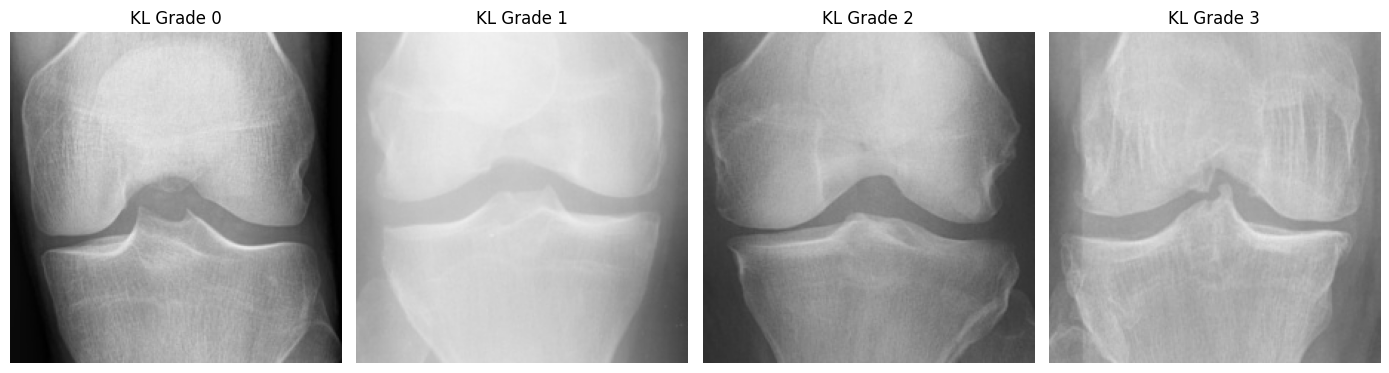

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for grade in range(4):
    folder = os.path.join(DATA_DIR, str(grade))
    files = [f for f in os.listdir(folder) if f.lower().endswith(".jpg")]

    img = Image.open(os.path.join(folder, files[0]))
    axes[grade].imshow(img, cmap="gray")
    axes[grade].set_title(f"KL Grade {grade}")
    axes[grade].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os
import random
import numpy as np
import pandas as pd
from PIL import Image
from pathlib import Path
from sklearn.model_selection import train_test_split

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Set reproducible seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATA_DIR = "/content/drive/MyDrive/kneeai"
SAVE_DIR = "/content/drive/MyDrive/kneeai_splits"
os.makedirs(SAVE_DIR, exist_ok=True)

# 1. Verification and Audit
image_paths = []
labels = []
corrupted = []

for grade in range(4):
    folder = os.path.join(DATA_DIR, str(grade))
    if not os.path.exists(folder):
        print(f"Warning: Folder {folder} does not exist.")
        continue

    for fname in os.listdir(folder):
        if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
            fpath = os.path.join(folder, fname)
            try:
                with Image.open(fpath) as img:
                    img.verify()
                image_paths.append(fpath)
                labels.append(grade)
            except Exception:
                corrupted.append(fpath)

print(f"Total valid images loaded: {len(image_paths)}")
print(f"Total corrupted images: {len(corrupted)}")
df_full = pd.DataFrame({'filepath': image_paths, 'label': labels})

# Deduplicate identical filepaths if any exist
df_full = df_full.drop_duplicates(subset=['filepath']).reset_index(drop=True)
print("Class distribution:\n", df_full['label'].value_counts().sort_index())

# 2. Stratified Train / Validation / Test Split (70 / 15 / 15)
train_df, temp_df = train_test_split(
    df_full, test_size=0.30, stratify=df_full['label'], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df['label'], random_state=SEED
)

# 3. Save splits
train_df.to_csv(os.path.join(SAVE_DIR, "train_split.csv"), index=False)
val_df.to_csv(os.path.join(SAVE_DIR, "val_split.csv"), index=False)
test_df.to_csv(os.path.join(SAVE_DIR, "test_split.csv"), index=False)
print("Stratified dataset splits successfully saved to Drive.")

# 4. PyTorch Dataset Definition & Transforms
class KneeDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'filepath']
        label = int(self.df.loc[idx, 'label'])
        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)
        return image, label

IMAGE_SIZE = 224

train_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

BATCH_SIZE = 32
train_loader = DataLoader(KneeDataset(train_df, train_transforms), batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(KneeDataset(val_df, eval_transforms), batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(KneeDataset(test_df, eval_transforms), batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

Total valid images loaded: 7828
Total corrupted images: 0
Class distribution:
 label
0    3085
1    1416
2    2062
3    1265
Name: count, dtype: int64
Stratified dataset splits successfully saved to Drive.


In [ ]:
import time
import torchvision.models as models
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import f1_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def get_model(model_name, num_classes=4):
    """Instantiates pretrained models and adapts the final classification head."""
    if model_name == "resnet18":
        model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif model_name == "resnet34":
        model = models.resnet34(weights=models.ResNet34_Weights.DEFAULT)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif model_name == "resnet50":
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif model_name == "densenet121":
        model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
        model.classifier = nn.Linear(model.classifier.in_features, num_classes)
    elif model_name == "densenet169":
        model = models.densenet169(weights=models.DenseNet169_Weights.DEFAULT)
        model.classifier = nn.Linear(model.classifier.in_features, num_classes)
    elif model_name == "efficientnet_b0":
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    elif model_name == "convnext_tiny":
        model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.DEFAULT)
        model.classifier[2] = nn.Linear(model.classifier[2].in_features, num_classes)
    elif model_name == "mobilenet_v3_large":
        model = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.DEFAULT)
        model.classifier[3] = nn.Linear(model.classifier[3].in_features, num_classes)
    else:
        raise ValueError(f"Unknown architecture: {model_name}")

    return model.to(device)


def freeze_backbone(model, freeze=True):
    """Freezes or unfreezes backbone parameters for warm-up training."""
    for name, param in model.named_parameters():
        if "fc" not in name and "classifier" not in name:
            param.requires_grad = not freeze


def train_epoch(model, dataloader, criterion, optimizer):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in dataloader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data).item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc


def validate_epoch(model, dataloader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += torch.sum(preds == labels.data).item()
            total += labels.size(0)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    macro_f1 = f1_score(all_labels, all_preds, average='macro')
    return epoch_loss, epoch_acc, macro_f1


def train_pipeline(model_name, train_loader, val_loader, max_epochs=50, warmup_epochs=3, patience=7):
    print(f"\n--- Starting Pipeline for: {model_name} ---")
    model = get_model(model_name)
    criterion = nn.CrossEntropyLoss()
    checkpoint_path = os.path.join(SAVE_DIR, f"{model_name}_best.pth")

    history = {
        'epoch': [], 'train_loss': [], 'train_acc': [],
        'val_loss': [], 'val_acc': [], 'val_macro_f1': []
    }

    best_val_f1 = 0.0
    patience_counter = 0
    start_time = time.time()

    # --- Phase 2A: Warm-up Epochs (Head Only) ---
    print(f"Warming up classification head for {warmup_epochs} epochs...")
    freeze_backbone(model, freeze=True)
    optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3)

    for epoch in range(1, warmup_epochs + 1):
        tr_loss, tr_acc = train_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc, val_f1 = validate_epoch(model, val_loader, criterion)
        print(f"[Warmup {epoch}/{warmup_epochs}] Train Loss: {tr_loss:.4f} | Val Loss: {val_loss:.4f} | Val Macro F1: {val_f1:.4f}")

    # --- Phase 2B: Full Fine-tuning ---
    print("Unfreezing model backbone for full fine-tuning...")
    freeze_backbone(model, freeze=False)
    optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)

    for epoch in range(warmup_epochs + 1, max_epochs + 1):
        tr_loss, tr_acc = train_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc, val_f1 = validate_epoch(model, val_loader, criterion)

        scheduler.step(val_f1)

        history['epoch'].append(epoch)
        history['train_loss'].append(tr_loss)
        history['train_acc'].append(tr_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['val_macro_f1'].append(val_f1)

        print(f"Epoch {epoch:02d}/{max_epochs:02d} | Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} Macro-F1: {val_f1:.4f}")

        # Checkpoint based on Validation Macro F1
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            torch.save(model.state_dict(), checkpoint_path)
            patience_counter = 0
            print(f" --> Best checkpoint saved (Val Macro F1: {best_val_f1:.4f})")
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping triggered at epoch {epoch}.")
                break

    total_time = time.time() - start_time
    history_df = pd.DataFrame(history)
    history_df.to_csv(os.path.join(SAVE_DIR, f"{model_name}_history.csv"), index=False)
    print(f"Training completed for {model_name} in {total_time/60:.2f} mins. Best Val Macro F1: {best_val_f1:.4f}")
    return history_df

In [ ]:
# Example execution:
resnet18_history = train_pipeline("resnet18", train_loader, val_loader, max_epochs=50, warmup_epochs=3, patience=7)


--- Starting Pipeline for: resnet18 ---
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 191MB/s]


Warming up classification head for 3 epochs...
[Warmup 1/3] Train Loss: 1.3277 | Val Loss: 1.2784 | Val Macro F1: 0.2209
[Warmup 2/3] Train Loss: 1.2565 | Val Loss: 1.2481 | Val Macro F1: 0.3637
[Warmup 3/3] Train Loss: 1.2235 | Val Loss: 1.2274 | Val Macro F1: 0.2905
Unfreezing model backbone for full fine-tuning...
Epoch 04/50 | Train Loss: 1.0082 Acc: 0.5691 | Val Loss: 0.8847 Acc: 0.6320 Macro-F1: 0.5833
 --> Best checkpoint saved (Val Macro F1: 0.5833)
Epoch 05/50 | Train Loss: 0.8546 Acc: 0.6419 | Val Loss: 0.8436 Acc: 0.6499 Macro-F1: 0.5464
Epoch 06/50 | Train Loss: 0.7892 Acc: 0.6671 | Val Loss: 0.8107 Acc: 0.6670 Macro-F1: 0.5534
Epoch 07/50 | Train Loss: 0.7503 Acc: 0.6875 | Val Loss: 0.8131 Acc: 0.6354 Macro-F1: 0.6291
 --> Best checkpoint saved (Val Macro F1: 0.6291)
Epoch 08/50 | Train Loss: 0.6944 Acc: 0.7087 | Val Loss: 0.8344 Acc: 0.6397 Macro-F1: 0.6376
 --> Best checkpoint saved (Val Macro F1: 0.6376)
Epoch 09/50 | Train Loss: 0.6632 Acc: 0.7213 | Val Loss: 0.8096 Ac

In [ ]:
model_candidates = [
    "resnet34", "resnet50",
    "densenet121", "densenet169",
    "efficientnet_b0", "convnext_tiny", "mobilenet_v3_large"
]

all_histories = {}

for model_name in model_candidates:
    print(f"\n==========================================")
    print(f"       STARTING TRAINING: {model_name}")
    print(f"==========================================")

    history_df = train_pipeline(
        model_name=model_name,
        train_loader=train_loader,
        val_loader=val_loader,
        max_epochs=50,
        warmup_epochs=3,
        patience=7
    )
    all_histories[model_name] = history_df


       STARTING TRAINING: resnet34

--- Starting Pipeline for: resnet34 ---
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 204MB/s]


Warming up classification head for 3 epochs...
[Warmup 1/3] Train Loss: 1.3116 | Val Loss: 1.2664 | Val Macro F1: 0.2489
[Warmup 2/3] Train Loss: 1.2453 | Val Loss: 1.2318 | Val Macro F1: 0.2794
[Warmup 3/3] Train Loss: 1.2207 | Val Loss: 1.2003 | Val Macro F1: 0.3317
Unfreezing model backbone for full fine-tuning...
Epoch 04/50 | Train Loss: 1.0190 Acc: 0.5660 | Val Loss: 0.9100 Acc: 0.6048 Macro-F1: 0.5042
 --> Best checkpoint saved (Val Macro F1: 0.5042)
Epoch 05/50 | Train Loss: 0.8466 Acc: 0.6401 | Val Loss: 0.8371 Acc: 0.6320 Macro-F1: 0.5511
 --> Best checkpoint saved (Val Macro F1: 0.5511)
Epoch 06/50 | Train Loss: 0.7732 Acc: 0.6762 | Val Loss: 0.7841 Acc: 0.6474 Macro-F1: 0.5935
 --> Best checkpoint saved (Val Macro F1: 0.5935)
Epoch 07/50 | Train Loss: 0.7399 Acc: 0.6884 | Val Loss: 0.8998 Acc: 0.6337 Macro-F1: 0.5365
Epoch 08/50 | Train Loss: 0.6938 Acc: 0.7071 | Val Loss: 0.8499 Acc: 0.6388 Macro-F1: 0.5991
 --> Best checkpoint saved (Val Macro F1: 0.5991)
Epoch 09/50 | Tr

100%|██████████| 97.8M/97.8M [00:00<00:00, 185MB/s]


Warming up classification head for 3 epochs...
[Warmup 1/3] Train Loss: 1.2946 | Val Loss: 1.2602 | Val Macro F1: 0.2450
[Warmup 2/3] Train Loss: 1.2461 | Val Loss: 1.2299 | Val Macro F1: 0.3036
[Warmup 3/3] Train Loss: 1.2279 | Val Loss: 1.2109 | Val Macro F1: 0.3153
Unfreezing model backbone for full fine-tuning...
Epoch 04/50 | Train Loss: 0.9916 Acc: 0.5694 | Val Loss: 0.9504 Acc: 0.5758 Macro-F1: 0.5073
 --> Best checkpoint saved (Val Macro F1: 0.5073)
Epoch 05/50 | Train Loss: 0.8090 Acc: 0.6592 | Val Loss: 0.8090 Acc: 0.6627 Macro-F1: 0.5570
 --> Best checkpoint saved (Val Macro F1: 0.5570)
Epoch 06/50 | Train Loss: 0.7448 Acc: 0.6810 | Val Loss: 0.7621 Acc: 0.6814 Macro-F1: 0.6068
 --> Best checkpoint saved (Val Macro F1: 0.6068)
Epoch 07/50 | Train Loss: 0.7013 Acc: 0.7060 | Val Loss: 0.7972 Acc: 0.6388 Macro-F1: 0.6219
 --> Best checkpoint saved (Val Macro F1: 0.6219)
Epoch 08/50 | Train Loss: 0.6532 Acc: 0.7282 | Val Loss: 0.7960 Acc: 0.6738 Macro-F1: 0.6082
Epoch 09/50 | Tr

100%|██████████| 30.8M/30.8M [00:00<00:00, 230MB/s]


... (7 outputs left out)

Warming up classification head for 3 epochs...
[Warmup 1/3] Train Loss: 1.2260 | Val Loss: 1.1862 | Val Macro F1: 0.3176
[Warmup 2/3] Train Loss: 1.1288 | Val Loss: 1.1009 | Val Macro F1: 0.4126
[Warmup 3/3] Train Loss: 1.0946 | Val Loss: 1.1170 | Val Macro F1: 0.3870
Unfreezing model backbone for full fine-tuning...
Epoch 04/50 | Train Loss: 1.0025 Acc: 0.5716 | Val Loss: 0.9637 Acc: 0.6167 Macro-F1: 0.5361
 --> Best checkpoint saved (Val Macro F1: 0.5361)
Epoch 05/50 | Train Loss: 0.7835 Acc: 0.6718 | Val Loss: 0.7370 Acc: 0.6985 Macro-F1: 0.6319
 --> Best checkpoint saved (Val Macro F1: 0.6319)
Epoch 06/50 | Train Loss: 0.7290 Acc: 0.6943 | Val Loss: 0.7600 Acc: 0.6806 Macro-F1: 0.5778
Epoch 07/50 | Train Loss: 0.6982 Acc: 0.7041 | Val Loss: 0.7222 Acc: 0.6882 Macro-F1: 0.5864
Epoch 08/50 | Train Loss: 0.6528 Acc: 0.7206 | Val Loss: 0.7159 Acc: 0.6831 Macro-F1: 0.6336
 --> Best checkpoint saved (Val Macro F1: 0.6336)
Epoch 09/50 | Train Loss: 0.6205 Acc: 0.7370 | Val Loss: 0.6814 Ac

100%|██████████| 21.1M/21.1M [00:00<00:00, 218MB/s]

Warming up classification head for 3 epochs...


[Warmup 1/3] Train Loss: 1.0581 | Val Loss: 1.2133 | Val Macro F1: 0.3723
[Warmup 2/3] Train Loss: 0.9113 | Val Loss: 0.9384 | Val Macro F1: 0.5232
[Warmup 3/3] Train Loss: 0.8582 | Val Loss: 0.8907 | Val Macro F1: 0.5380
Unfreezing model backbone for full fine-tuning...
Epoch 04/50 | Train Loss: 0.7913 Acc: 0.6667 | Val Loss: 0.8113 Acc: 0.6533 Macro-F1: 0.5696
 --> Best checkpoint saved (Val Macro F1: 0.5696)
Epoch 05/50 | Train Loss: 0.7427 Acc: 0.6817 | Val Loss: 0.8231 Acc: 0.6635 Macro-F1: 0.5986
 --> Best checkpoint saved (Val Macro F1: 0.5986)
Epoch 06/50 | Train Loss: 0.7143 Acc: 0.7023 | Val Loss: 0.7744 Acc: 0.6797 Macro-F1: 0.6225
 --> Best checkpoint saved (Val Macro F1: 0.6225)
Epoch 07/50 | Train Loss: 0.6799 Acc: 0.7072 | Val Loss: 0.7886 Acc: 0.6610 Macro-F1: 0.5964
Epoch 08/50 | Train Loss: 0.6661 Acc: 0.7160 | Val Loss: 0.8041 Acc: 0.6712 Macro-F1: 0.6156
Epoch 09/50 | Train Loss: 0.6232 Acc: 0.7412 | Val Loss: 0.7855 Acc: 0.6721 Macro-F1: 0.5905
Epoch 10/50 | Train 

In [ ]:
import os
import pandas as pd
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms

# Define KneeDataset and required transforms to make this cell self-contained
class KneeDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'filepath']
        label = int(self.df.loc[idx, 'label'])
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

IMAGE_SIZE = 224
BATCH_SIZE = 32

train_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

SAVE_DIR = "/content/drive/MyDrive/kneeai_splits"
train_split_path = os.path.join(SAVE_DIR, "train_split.csv")

if os.path.exists(train_split_path):
    # Load the train dataframe from the saved CSV
    train_df = pd.read_csv(train_split_path)

    # Compute weight per sample in train set
    class_counts = train_df['label'].value_counts().to_dict()
    class_weights = {cls: 1.0 / count for cls, count in class_counts.items()}
    sample_weights = train_df['label'].map(class_weights).values

    # Create Sampler
    sampler = WeightedRandomSampler(
        weights=torch.tensor(sample_weights, dtype=torch.double),
        num_samples=len(sample_weights),
        replacement=True
    )

    # Note: shuffle must be False when using a sampler
    train_loader = DataLoader(
        KneeDataset(train_df, train_transforms),
        batch_size=BATCH_SIZE,
        sampler=sampler,
        num_workers=2,
        pin_memory=True
    )
    print("Weighted sampler and train_loader successfully initialized using saved splits.")
else:
    print(f"Error: {train_split_path} not found. Please run your dataset split cell first to generate the CSV files.")

Weighted sampler and train_loader successfully initialized using saved splits.


In [ ]:
import os
import random
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split

import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms

# Set reproducible seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATA_DIR = "/content/drive/MyDrive/kneeai"
SAVE_DIR = "/content/drive/MyDrive/kneeai_splits"
os.makedirs(SAVE_DIR, exist_ok=True)

# 1. Audit and Load Filepaths
image_paths = []
labels = []

for grade in range(4):
    folder = os.path.join(DATA_DIR, str(grade))
    if not os.path.exists(folder):
        continue
    for fname in os.listdir(folder):
        if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
            fpath = os.path.join(folder, fname)
            try:
                with Image.open(fpath) as img:
                    img.verify()
                image_paths.append(fpath)
                labels.append(grade)
            except Exception:
                pass

df_full = pd.DataFrame({'filepath': image_paths, 'label': labels}).drop_duplicates(subset=['filepath']).reset_index(drop=True)

# 2. Stratified Train / Validation / Test Split (70 / 15 / 15)
train_df, temp_df = train_test_split(df_full, test_size=0.30, stratify=df_full['label'], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=SEED)

# Print Class Counts to verify imbalance
print("Original Training Class Counts:\n", train_df['label'].value_counts().sort_index())

# 3. Create WeightedRandomSampler for Training Set
class_counts = train_df['label'].value_counts().to_dict()
class_weights = {cls: 1.0 / count for cls, count in class_counts.items()}
sample_weights = train_df['label'].map(class_weights).values

sampler = WeightedRandomSampler(
    weights=torch.tensor(sample_weights, dtype=torch.double),
    num_samples=len(sample_weights),
    replacement=True
)

# 4. PyTorch Dataset Definition & Transforms
class KneeDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'filepath']
        label = int(self.df.loc[idx, 'label'])
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

IMAGE_SIZE = 224

train_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

BATCH_SIZE = 32

# Note: shuffle MUST be False when sampler is provided
train_loader = DataLoader(
    KneeDataset(train_df, train_transforms),
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(KneeDataset(val_df, eval_transforms), batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(KneeDataset(test_df, eval_transforms), batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

Original Training Class Counts:
 label
0    2159
1     991
2    1443
3     886
Name: count, dtype: int64


In [ ]:
import os

from google.colab import drive
drive.mount('/content/drive')

root = "/content/drive/MyDrive"

print("Searching for trained PyTorch models...\n")

for folder, _, files in os.walk(root):
    for file in files:
        if file.endswith((".pth", ".pt")):
            print(os.path.join(folder, file))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Searching for trained PyTorch models...

/content/drive/MyDrive/kneeai/best_kneecare_resnet18.pth
/content/drive/MyDrive/kneeai/best_kneecare_resnet18_augmented.pth
/content/drive/MyDrive/kneeai/best_kneecare_grade1_experiment.pth
/content/drive/MyDrive/kneeai/best_kneecare_balanced_experiment.pth
/content/drive/MyDrive/kneeai/experiments/googlenet_50_epochs_v1/checkpoints/best_googlenet.pth
/content/drive/MyDrive/kneeai/experiments/googlenet_50_epochs_fresh_v2/checkpoints/best_googlenet.pth
/content/drive/MyDrive/kneeai/experiments/googlenet_50_epochs_fresh_v2/checkpoints/latest_googlenet.pth
/content/drive/MyDrive/kneeai_splits/resnet18_best.pth
/content/drive/MyDrive/kneeai_splits/resnet34_best.pth
/content/drive/MyDrive/kneeai_splits/resnet50_best.pth
/content/drive/MyDrive/kneeai_splits/densenet121_best.pth
/content/drive/MyDrive/kneeai_splits/densenet16

In [ ]:
import torch
import os

files = [
    "/content/drive/MyDrive/kneeai/best_kneecare_resnet18.pth",
    "/content/drive/MyDrive/kneeai/best_kneecare_resnet18_augmented.pth",
    "/content/drive/MyDrive/kneeai/best_kneecare_grade1_experiment.pth",
    "/content/drive/MyDrive/kneeai/best_kneecare_balanced_experiment.pth",
    "/content/drive/MyDrive/kneeai_splits/resnet18_best.pth",
    "/content/drive/MyDrive/kneeai_splits/resnet34_best.pth",
    "/content/drive/MyDrive/kneeai_splits/resnet50_best.pth",
    "/content/drive/MyDrive/kneeai_splits/densenet121_best.pth",
    "/content/drive/MyDrive/kneeai_splits/convnext_tiny_best.pth"
]

for path in files:
    print("\n" + "=" * 60)
    print("MODEL:", os.path.basename(path))

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    if isinstance(checkpoint, dict):
        print("Checkpoint keys:", list(checkpoint.keys()))

        for key, value in checkpoint.items():
            if isinstance(value, (int, float, str, bool)):
                print(f"{key}: {value}")

    else:
        print("Checkpoint type:", type(checkpoint))


MODEL: best_kneecare_resnet18.pth
Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_loss']
epoch: 2
best_val_loss: 0.9264298654089997

MODEL: best_kneecare_resnet18_augmented.pth
Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_loss']
epoch: 3
best_val_loss: 0.8334760458749645

MODEL: best_kneecare_grade1_experiment.pth
Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_loss', 'class_weights']
epoch: 4
best_val_loss: 0.8338792816540654

MODEL: best_kneecare_balanced_experiment.pth
Checkpoint keys: ['epoch', 'model_state_dict', 'optimizer_state_dict', 'best_val_loss', 'class_weights']
epoch: 5
best_val_loss: 0.8335277184310926

MODEL: resnet18_best.pth
Checkpoint keys: ['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.conv1.weight', 'layer1.0.bn1.weight', 'layer1.0.bn1.bias', 'layer1.0.bn1.running_mean', 'layer1.0.bn1.running_

In [ ]:
import torch
import os

models = {
    "ResNet18": "/content/drive/MyDrive/kneeai_splits/resnet18_best.pth",
    "ResNet34": "/content/drive/MyDrive/kneeai_splits/resnet34_best.pth",
    "ResNet50": "/content/drive/MyDrive/kneeai_splits/resnet50_best.pth",
    "DenseNet121": "/content/drive/MyDrive/kneeai_splits/densenet121_best.pth",
    "ConvNeXt-Tiny": "/content/drive/MyDrive/kneeai_splits/convnext_tiny_best.pth"
}

for name, path in models.items():
    checkpoint = torch.load(
        path, map_location="cpu", weights_only=True
    )

    if "model_state_dict" in checkpoint:
        weights = checkpoint["model_state_dict"]
    else:
        weights = checkpoint

    print("\nModel:", name)

    for key in ["fc.weight", "classifier.weight",
                "classifier.2.weight"]:
        if key in weights:
            print("Output classes:", weights[key].shape[0])
            break


Model: ResNet18
Output classes: 4

Model: ResNet34
Output classes: 4

Model: ResNet50
Output classes: 4

Model: DenseNet121
Output classes: 4

Model: ConvNeXt-Tiny
Output classes: 4


In [ ]:
import os

folders = [
    "/content/drive/MyDrive/kneeai_splits",
    "/content/drive/MyDrive/KneeCareAI_Improved",
    "/content/drive/MyDrive/kneeai"
]

extensions = (".csv", ".json", ".txt", ".yaml", ".yml")

for folder in folders:
    print(f"\n--- {folder} ---")

    if not os.path.exists(folder):
        print("Folder not found")
        continue

    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.lower().endswith(extensions):
                print(os.path.join(root, file))


--- /content/drive/MyDrive/kneeai_splits ---
/content/drive/MyDrive/kneeai_splits/train_split.csv
/content/drive/MyDrive/kneeai_splits/val_split.csv
/content/drive/MyDrive/kneeai_splits/test_split.csv
/content/drive/MyDrive/kneeai_splits/resnet18_history.csv
/content/drive/MyDrive/kneeai_splits/resnet34_history.csv
/content/drive/MyDrive/kneeai_splits/resnet50_history.csv
/content/drive/MyDrive/kneeai_splits/densenet121_history.csv
/content/drive/MyDrive/kneeai_splits/densenet169_history.csv
/content/drive/MyDrive/kneeai_splits/efficientnet_b0_history.csv
/content/drive/MyDrive/kneeai_splits/convnext_tiny_history.csv
/content/drive/MyDrive/kneeai_splits/mobilenet_v3_large_history.csv
/content/drive/MyDrive/kneeai_splits/train.csv
/content/drive/MyDrive/kneeai_splits/val.csv
/content/drive/MyDrive/kneeai_splits/test.csv

--- /content/drive/MyDrive/KneeCareAI_Improved ---
/content/drive/MyDrive/KneeCareAI_Improved/splits/train.csv
/content/drive/MyDrive/KneeCareAI_Improved/splits/val.cs

In [ ]:
import os
import glob
import pandas as pd

folder = "/content/drive/MyDrive/kneeai_splits"

history_files = glob.glob(
    os.path.join(folder, "*_history.csv")
)

for path in sorted(history_files):

    model_name = os.path.basename(path).replace(
        "_history.csv", ""
    )

    df = pd.read_csv(path)

    print("\n" + "=" * 60)
    print("MODEL:", model_name)
    print("Columns:", list(df.columns))
    print("Total epochs:", len(df))

    # Find validation loss column
    loss_col = next(
        (c for c in df.columns
         if c.lower() in ["val_loss", "validation_loss"]),
        None
    )

    # Find validation accuracy column
    acc_col = next(
        (c for c in df.columns
         if c.lower() in [
             "val_accuracy", "val_acc",
             "validation_accuracy"
         ]),
        None
    )

    if loss_col:
        best = df.loc[df[loss_col].idxmin()]
        print("\nBest validation loss:")
        print(best.to_string())

    elif acc_col:
        best = df.loc[df[acc_col].idxmax()]
        print("\nBest validation accuracy:")
        print(best.to_string())

    else:
        print("\nCould not automatically identify validation metrics.")
        print(df.tail().to_string(index=False))


MODEL: convnext_tiny
Columns: ['epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'val_macro_f1']
Total epochs: 39

Best validation loss:
epoch           9.000000
train_loss      0.620462
train_acc       0.736996
val_loss        0.681394
val_acc         0.729983
val_macro_f1    0.687194

MODEL: densenet121
Columns: ['epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'val_macro_f1']
Total epochs: 35

Best validation loss:
epoch           11.000000
train_loss       0.520838
train_acc        0.791933
val_loss         0.723119
val_acc          0.716354
val_macro_f1     0.693893

MODEL: densenet169
Columns: ['epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'val_macro_f1']
Total epochs: 20

Best validation loss:
epoch           10.000000
train_loss       0.529341
train_acc        0.787918
val_loss         0.717923
val_acc          0.709540
val_macro_f1     0.681291

MODEL: efficientnet_b0
Columns: ['epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'val_mac

In [ ]:
import pandas as pd
import os

folder = "/content/drive/MyDrive/kneeai_splits"

for name in [
    "train_split.csv", "val_split.csv", "test_split.csv",
    "train.csv", "val.csv", "test.csv"
]:
    path = os.path.join(folder, name)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print(f"\n{name}")
        print("Rows:", len(df))
        print("Columns:", list(df.columns))
        print(df.head(2).to_string(index=False))


train_split.csv
Rows: 5479
Columns: ['filepath', 'label']
                                      filepath  label
/content/drive/MyDrive/kneeai/3/Image_7496.jpg      3
/content/drive/MyDrive/kneeai/0/Image_6076.jpg      0

val_split.csv
Rows: 1174
Columns: ['filepath', 'label']
                                      filepath  label
/content/drive/MyDrive/kneeai/0/Image_1001.jpg      0
/content/drive/MyDrive/kneeai/1/Image_7392.jpg      1

test_split.csv
Rows: 1175
Columns: ['filepath', 'label']
                                      filepath  label
/content/drive/MyDrive/kneeai/0/Image_1521.jpg      0
/content/drive/MyDrive/kneeai/0/Image_1780.jpg      0

train.csv
Rows: 5479
Columns: ['filepath', 'label']
                                      filepath  label
/content/drive/MyDrive/kneeai/3/Image_5950.jpg      3
/content/drive/MyDrive/kneeai/0/Image_1370.jpg      0

val.csv
Rows: 1174
Columns: ['filepath', 'label']
                                      filepath  label
 /content/drive/MyDr

In [ ]:
import pandas as pd
import os

folder = "/content/drive/MyDrive/kneeai_splits"

pairs = [
    ("train_split.csv", "train.csv"),
    ("val_split.csv", "val.csv"),
    ("test_split.csv", "test.csv")
]

for file1, file2 in pairs:
    df1 = pd.read_csv(os.path.join(folder, file1))
    df2 = pd.read_csv(os.path.join(folder, file2))

    set1 = set(zip(df1["filepath"], df1["label"]))
    set2 = set(zip(df2["filepath"], df2["label"]))

    print("\n", file1, "vs", file2)
    print("Same images and labels:", set1 == set2)
    print("Only in first:", len(set1 - set2))
    print("Only in second:", len(set2 - set1))

print("\n--- Split overlap check ---")

for prefix in ["train_split", ""]:
    train_name = "train_split.csv" if prefix else "train.csv"
    val_name = "val_split.csv" if prefix else "val.csv"
    test_name = "test_split.csv" if prefix else "test.csv"

    train = set(pd.read_csv(os.path.join(folder, train_name))["filepath"])
    val = set(pd.read_csv(os.path.join(folder, val_name))["filepath"])
    test = set(pd.read_csv(os.path.join(folder, test_name))["filepath"])

    print(f"\n{prefix or 'standard'}")
    print("Train-validation overlap:", len(train & val))
    print("Train-test overlap:", len(train & test))
    print("Validation-test overlap:", len(val & test))


 train_split.csv vs train.csv
Same images and labels: False
Only in first: 1656
Only in second: 1656

 val_split.csv vs val.csv
Same images and labels: False
Only in first: 1007
Only in second: 1007

 test_split.csv vs test.csv
Same images and labels: False
Only in first: 1008
Only in second: 1008

--- Split overlap check ---

train_split
Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0

standard
Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0


In [ ]:
import os

root = "/content/drive/MyDrive"

for folder in [
    "kneeai_splits",
    "KneeCareAI_Improved",
    "kneeai"
]:
    path = os.path.join(root, folder)

    print("\n==========", folder, "==========")

    for current, dirs, files in os.walk(path):
        dirs[:] = [
            d for d in dirs
            if d not in ["0", "1", "2", "3"]
        ]

        for file in files:
            if file.endswith((".py", ".json")):
                print(os.path.join(current, file))


========== kneeai_splits ==========

========== KneeCareAI_Improved ==========

========== kneeai ==========
/content/drive/MyDrive/kneeai/kneecare_config.json
/content/drive/MyDrive/kneeai/experiments/googlenet_50_epochs_v1/configs/googlenet_config.json
/content/drive/MyDrive/kneeai/dataset_audit/audit_results.json


In [ ]:
import os
import json
import pandas as pd

base = "/content/drive/MyDrive"

# 1. Inspect saved configurations
config_files = [
    "kneeai/kneecare_config.json",
    "kneeai/experiments/googlenet_50_epochs_v1/configs/googlenet_config.json",
    "kneeai/experiments/googlenet_50_epochs_fresh_v2/configs/googlenet_config.json"
]

for relative_path in config_files:
    path = os.path.join(base, relative_path)

    print("\n==========", relative_path, "==========")

    if os.path.exists(path):
        with open(path, "r") as f:
            print(json.dumps(json.load(f), indent=2))
    else:
        print("File not found")

# 2. Inspect class distributions in both split sets
folder = os.path.join(base, "kneeai_splits")

for name in [
    "train_split.csv", "val_split.csv", "test_split.csv",
    "train.csv", "val.csv", "test.csv"
]:
    path = os.path.join(folder, name)
    df = pd.read_csv(path)

    print(f"\n{name}")
    print("Total images:", len(df))
    print("Class distribution:")
    print(df["label"].value_counts().sort_index().to_dict())

# 3. Check the audited split file
audit_path = os.path.join(
    base, "kneeai", "dataset_audit", "verified_splits.csv"
)

if os.path.exists(audit_path):
    audit = pd.read_csv(audit_path)
    print("\nVerified splits file")
    print("Columns:", list(audit.columns))
    print("Rows:", len(audit))
    print(audit.head().to_string(index=False))


========== kneeai/kneecare_config.json ==========
{
  "model_name": "ResNet18",
  "num_classes": 4,
  "classes": [
    0,
    1,
    2,
    3
  ],
  "image_size": [
    224,
    224
  ],
  "normalization_mean": [
    0.485,
    0.456,
    0.406
  ],
  "normalization_std": [
    0.229,
    0.224,
    0.225
  ],
  "training_augmentation": {
    "random_rotation": 7,
    "horizontal_flip": 0.5,
    "brightness": 0.1,
    "contrast": 0.1
  },
  "optimizer": "AdamW",
  "learning_rate": 0.0001,
  "weight_decay": 0.0001,
  "batch_size": 32,
  "best_epoch": 3
}

========== kneeai/experiments/googlenet_50_epochs_v1/configs/googlenet_config.json ==========
{
  "architecture": "GoogLeNet",
  "pretrained_weights": "ImageNet",
  "num_classes": 4,
  "class_names": [
    "Grade 0",
    "Grade 1",
    "Grade 2",
    "Grade 3"
  ],
  "image_size": 224,
  "batch_size": 32,
  "max_epochs": 50,
  "optimizer": "AdamW",
  "learning_rate": 0.0001,
  "weight_decay": 0.0001,
  "loss": "Weighted CrossEntropyLo

In [ ]:
import pandas as pd
import os

folder = "/content/drive/MyDrive/kneeai_splits"

verified_path = (
    "/content/drive/MyDrive/kneeai/dataset_audit/verified_splits.csv"
)

verified = pd.read_csv(verified_path)

for split in ["train", "val", "test"]:

    verified_df = verified[verified["split"] == split]

    standard_df = pd.read_csv(
        os.path.join(folder, f"{split}.csv")
    )

    split_df = pd.read_csv(
        os.path.join(folder, f"{split}_split.csv")
    )

    verified_set = set(zip(
        verified_df["filename"],
        verified_df["label"]
    ))

    standard_set = set(zip(
        standard_df["filepath"],
        standard_df["label"]
    ))

    split_set = set(zip(
        split_df["filepath"],
        split_df["label"]
    ))

    print(f"\n{split.upper()}")
    print("Verified matches standard CSV:", verified_set == standard_set)
    print("Verified matches split CSV:", verified_set == split_set)


TRAIN
Verified matches standard CSV: True
Verified matches split CSV: False

VAL
Verified matches standard CSV: False
Verified matches split CSV: False

TEST
Verified matches standard CSV: True
Verified matches split CSV: False


In [ ]:
import pandas as pd
import os

base = "/content/drive/MyDrive"

verified = pd.read_csv(
    f"{base}/kneeai/dataset_audit/verified_splits.csv"
)

folder = f"{base}/kneeai_splits"

verified_val = verified[verified["split"] == "val"]

print("Verified validation images:", len(verified_val))

for name in ["val.csv", "val_split.csv"]:
    df = pd.read_csv(os.path.join(folder, name))

    verified_set = set(
        zip(verified_val["filename"], verified_val["label"])
    )

    current_set = set(zip(df["filepath"], df["label"]))

    print(f"\n{name}")
    print("Matching images:", len(verified_set & current_set))
    print("Different images:", len(verified_set - current_set))

print("\nVerified validation class distribution:")
print(verified_val["label"].value_counts().sort_index())

Verified validation images: 0

val.csv
Matching images: 0
Different images: 0

val_split.csv
Matching images: 0
Different images: 0

Verified validation class distribution:
Series([], Name: count, dtype: int64)


In [ ]:
import pandas as pd

path = "/content/drive/MyDrive/kneeai/dataset_audit/verified_splits.csv"

df = pd.read_csv(path)

print("Split names:")
print(df["split"].value_counts(dropna=False))

print("\nUnique split values:")
print(df["split"].unique())

Split names:
split
train         5479
test          1175
validation    1174
Name: count, dtype: int64

Unique split values:
['train' 'validation' 'test']


In [ ]:
import pandas as pd
import os

folder = "/content/drive/MyDrive/kneeai_splits"

verified = pd.read_csv(
    "/content/drive/MyDrive/kneeai/dataset_audit/verified_splits.csv"
)

split_names = {
    "train": "train",
    "val": "validation",
    "test": "test"
}

for csv_name, verified_name in split_names.items():

    verified_df = verified[
        verified["split"] == verified_name
    ]

    standard_df = pd.read_csv(
        os.path.join(folder, f"{csv_name}.csv")
    )

    alternate_df = pd.read_csv(
        os.path.join(folder, f"{csv_name}_split.csv")
    )

    verified_set = set(zip(
        verified_df["filename"], verified_df["label"]
    ))

    standard_set = set(zip(
        standard_df["filepath"], standard_df["label"]
    ))

    alternate_set = set(zip(
        alternate_df["filepath"], alternate_df["label"]
    ))

    print(f"\n{csv_name.upper()}")
    print("Standard CSV matches verified:",
          verified_set == standard_set)
    print("Alternate CSV matches verified:",
          verified_set == alternate_set)


TRAIN
Standard CSV matches verified: True
Alternate CSV matches verified: False

VAL
Standard CSV matches verified: True
Alternate CSV matches verified: False

TEST
Standard CSV matches verified: True
Alternate CSV matches verified: False


In [ ]:
import os
import torch

folder = "/content/drive/MyDrive/kneeai_splits"

models = {
    "ResNet18": "resnet18_best.pth",
    "ResNet34": "resnet34_best.pth",
    "ResNet50": "resnet50_best.pth",
    "DenseNet121": "densenet121_best.pth",
    "DenseNet169": "densenet169_best.pth",
    "EfficientNet-B0": "efficientnet_b0_best.pth",
    "ConvNeXt-Tiny": "convnext_tiny_best.pth",
    "MobileNetV3-Large": "mobilenet_v3_large_best.pth"
}

for name, filename in models.items():
    path = os.path.join(folder, filename)

    print("\n" + "=" * 50)
    print("MODEL:", name)

    if not os.path.exists(path):
        print("Checkpoint not found:", path)
        continue

    checkpoint = torch.load(
        path, map_location="cpu", weights_only=True
    )

    print("File size (MB):", round(os.path.getsize(path) / (1024**2), 2))

    if isinstance(checkpoint, dict):
        print("Top-level keys:", list(checkpoint.keys())[:15])

        weights = checkpoint

        for key in ["model_state_dict", "state_dict", "model"]:
            if key in checkpoint and isinstance(checkpoint[key], dict):
                weights = checkpoint[key]
                break

        print("Weight entries:", len(weights))

        head_keys = [
            (key, tuple(value.shape))
            for key, value in weights.items()
            if isinstance(value, torch.Tensor)
            and (
                "classifier" in key
                or "fc." in key
                or "head." in key
            )
            and key.endswith("weight")
        ]

        print("Classification head candidates:", head_keys[-8:])
    else:
        print("Unexpected checkpoint format:", type(checkpoint))


MODEL: ResNet18
File size (MB): 42.72
Top-level keys: ['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.conv1.weight', 'layer1.0.bn1.weight', 'layer1.0.bn1.bias', 'layer1.0.bn1.running_mean', 'layer1.0.bn1.running_var', 'layer1.0.bn1.num_batches_tracked', 'layer1.0.conv2.weight', 'layer1.0.bn2.weight', 'layer1.0.bn2.bias']
Weight entries: 122
Classification head candidates: [('fc.weight', (4, 512))]

MODEL: ResNet34
File size (MB): 81.34
Top-level keys: ['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.conv1.weight', 'layer1.0.bn1.weight', 'layer1.0.bn1.bias', 'layer1.0.bn1.running_mean', 'layer1.0.bn1.running_var', 'layer1.0.bn1.num_batches_tracked', 'layer1.0.conv2.weight', 'layer1.0.bn2.weight', 'layer1.0.bn2.bias']
Weight entries: 218
Classification head candidates: [('fc.weight', (4, 512))]

MODEL: ResNet50
File size (MB): 90.01
Top-level keys:

In [ ]:
import pandas as pd
import os
import glob

folder = "/content/drive/MyDrive/kneeai_splits"

for path in sorted(glob.glob(folder + "/*_history.csv")):
    name = os.path.basename(path).replace("_history.csv", "")
    df = pd.read_csv(path)

    best_acc = df.loc[df["val_acc"].idxmax()]
    best_f1 = df.loc[df["val_macro_f1"].idxmax()]
    best_loss = df.loc[df["val_loss"].idxmin()]

    print("\n" + "=" * 55)
    print("MODEL:", name)

    print(
        "Best validation accuracy:",
        round(best_acc["val_acc"] * 100, 2), "%",
        "| Epoch:", int(best_acc["epoch"])
    )

    print(
        "Best macro F1:",
        round(best_f1["val_macro_f1"], 4),
        "| Epoch:", int(best_f1["epoch"])
    )

    print(
        "Lowest validation loss:",
        round(best_loss["val_loss"], 4),
        "| Epoch:", int(best_loss["epoch"])
    )


MODEL: convnext_tiny
Best validation accuracy: 75.72 % | Epoch: 33
Best macro F1: 0.7329 | Epoch: 35
Lowest validation loss: 0.6814 | Epoch: 9

MODEL: densenet121
Best validation accuracy: 74.87 % | Epoch: 38
Best macro F1: 0.7236 | Epoch: 31
Lowest validation loss: 0.7231 | Epoch: 11

MODEL: densenet169
Best validation accuracy: 74.53 % | Epoch: 19
Best macro F1: 0.7126 | Epoch: 16
Lowest validation loss: 0.7179 | Epoch: 10

MODEL: efficientnet_b0
Best validation accuracy: 70.7 % | Epoch: 23
Best macro F1: 0.6846 | Epoch: 16
Lowest validation loss: 0.7366 | Epoch: 10

MODEL: mobilenet_v3_large
Best validation accuracy: 68.99 % | Epoch: 10
Best macro F1: 0.6597 | Epoch: 14
Lowest validation loss: 0.7744 | Epoch: 6

MODEL: resnet18
Best validation accuracy: 71.12 % | Epoch: 20
Best macro F1: 0.6835 | Epoch: 22
Lowest validation loss: 0.7818 | Epoch: 12

MODEL: resnet34
Best validation accuracy: 72.23 % | Epoch: 27
Best macro F1: 0.6959 | Epoch: 26
Lowest validation loss: 0.7488 | Epoch

In [ ]:
import os
import json

root = "/content/drive/MyDrive"

terms = [
    "resnet18_history.csv",
    "convnext_tiny_history.csv",
    "resnet18_best.pth",
    "convnext_tiny_best.pth",
    "train_split.csv",
    "train.csv"
]

print("SEARCHING TRAINING NOTEBOOKS...\n")

for current, dirs, files in os.walk(root):

    dirs[:] = [
        d for d in dirs
        if d not in [".ipynb_checkpoints", "__pycache__"]
    ]

    for file in files:

        if not file.endswith((".ipynb", ".py")):
            continue

        path = os.path.join(current, file)

        try:
            with open(path, "r", encoding="utf-8") as f:
                content = f.read()

            matches = [term for term in terms if term in content]

            if matches:
                print("\nFILE:", path)
                print("MATCHES:", matches)

        except Exception:
            pass

SEARCHING TRAINING NOTEBOOKS...


FILE: /content/drive/MyDrive/Colab Notebooks/kneeai_res18vsres34.ipynb
MATCHES: ['resnet18_history.csv', 'convnext_tiny_history.csv', 'resnet18_best.pth', 'convnext_tiny_best.pth', 'train_split.csv', 'train.csv']


In [ ]:
import json

path = "/content/drive/MyDrive/Colab Notebooks/kneeai_res18vsres34.ipynb"

with open(path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "train_split.csv",
    "val_split.csv",
    "train.csv",
    "val.csv",
    "torch.save",
    "best_val",
    "best_model",
    "val_loss",
    "val_acc",
    "transforms.",
    "DataLoader",
    "history.csv"
]

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))

    if any(word in source for word in keywords):
        print("\n" + "=" * 70)
        print("CELL:", i, "| TYPE:", cell["cell_type"])
        print(source)


CELL: 7 | TYPE: code
import os
import random
import numpy as np
import pandas as pd
from PIL import Image
from pathlib import Path
from sklearn.model_selection import train_test_split

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Set reproducible seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATA_DIR = "/content/drive/MyDrive/kneeai"
SAVE_DIR = "/content/drive/MyDrive/kneeai_splits"
os.makedirs(SAVE_DIR, exist_ok=True)

# 1. Verification and Audit
image_paths = []
labels = []
corrupted = []

for grade in range(4):
    folder = os.path.join(DATA_DIR, str(grade))
    if not os.path.exists(folder):
        print(f"Warning: Folder {folder} does not exist.")
        continue

    for fname in os.listdir(folder):
        if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
            fpath = os.path.join(folder, fname)
            try:

In [ ]:
if val_f1 > best_val_f1:
    best_val_f1 = val_f1
    torch.save(model.state_dict(), checkpoint_path)

NameError: name 'val_f1' is not defined

In [ ]:
import pandas as pd
import os

folder = "/content/drive/MyDrive/kneeai_splits"

for name in [
    "resnet18_history.csv",
    "resnet34_history.csv",
    "resnet50_history.csv",
    "densenet121_history.csv",
    "densenet169_history.csv",
    "efficientnet_b0_history.csv",
    "convnext_tiny_history.csv",
    "mobilenet_v3_large_history.csv"
]:
    path = os.path.join(folder, name)
    df = pd.read_csv(path)

    print("\n", name)
    print("First recorded epoch:")
    print(df.iloc[0].to_dict())

    print("Best macro F1:")
    print(df.loc[df["val_macro_f1"].idxmax()].to_dict())

    print("Last recorded epoch:")
    print(df.iloc[-1].to_dict())


 resnet18_history.csv
First recorded epoch:
{'epoch': 4.0, 'train_loss': 1.0082266507281028, 'train_acc': 0.569081949260814, 'val_loss': 0.884697355342683, 'val_acc': 0.6320272572402045, 'val_macro_f1': 0.5832595715878924}
Best macro F1:
{'epoch': 22.0, 'train_loss': 0.1561805131330305, 'train_acc': 0.9450629676948348, 'val_loss': 0.9861958276677172, 'val_acc': 0.7044293015332198, 'val_macro_f1': 0.6834977424304023}
Last recorded epoch:
{'epoch': 29.0, 'train_loss': 0.0766305761314217, 'train_acc': 0.9762730425260084, 'val_loss': 1.0837897687795013, 'val_acc': 0.6976149914821125, 'val_macro_f1': 0.676583199111666}

 resnet34_history.csv
First recorded epoch:
{'epoch': 4.0, 'train_loss': 1.019022480635165, 'train_acc': 0.5659791932834459, 'val_loss': 0.9100405823636096, 'val_acc': 0.6047700170357752, 'val_macro_f1': 0.5041645207200665}
Best macro F1:
{'epoch': 26.0, 'train_loss': 0.0741067656490433, 'train_acc': 0.9755429822960394, 'val_loss': 1.169504454432395, 'val_acc': 0.7172061328

In [ ]:
if val_f1 > best_val_f1:
    best_val_f1 = val_f1
    torch.save(model.state_dict(), checkpoint_path)

NameError: name 'val_f1' is not defined

In [ ]:
import json

path = "/content/drive/MyDrive/Colab Notebooks/kneeai_res18vsres34.ipynb"

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

for i in [7, 8, 9, 10, 11, 12]:
    cell = nb["cells"][i]

    print("\n" + "=" * 60)
    print("CELL:", i)

    for output in cell.get("outputs", []):
        if "text" in output:
            print("".join(output["text"]))
        elif "data" in output and "text/plain" in output["data"]:
            print("".join(output["data"]["text/plain"]))


CELL: 7
Total valid images loaded: 7828
Total corrupted images: 0
Class distribution:
 label
0    3085
1    1416
2    2062
3    1265
Name: count, dtype: int64
Stratified dataset splits successfully saved to Drive.


CELL: 8

CELL: 9

--- Starting Pipeline for: resnet18 ---
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth

100%|██████████| 44.7M/44.7M [00:00<00:00, 191MB/s]

Warming up classification head for 3 epochs...
[Warmup 1/3] Train Loss: 1.3277 | Val Loss: 1.2784 | Val Macro F1: 0.2209
[Warmup 2/3] Train Loss: 1.2565 | Val Loss: 1.2481 | Val Macro F1: 0.3637
[Warmup 3/3] Train Loss: 1.2235 | Val Loss: 1.2274 | Val Macro F1: 0.2905
Unfreezing model backbone for full fine-tuning...
Epoch 04/50 | Train Loss: 1.0082 Acc: 0.5691 | Val Loss: 0.8847 Acc: 0.6320 Macro-F1: 0.5833
 --> Best checkpoint saved (Val Macro F1: 0.5833)
Epoch 05/50 | Train Loss: 0.8546 Acc: 0.6419 | Val Loss: 0.8436 Acc: 0.6499 

In [ ]:
import shutil
import os

LOCAL_DATA_DIR = "/content/kneeai_local"
if not os.path.exists(LOCAL_DATA_DIR):
    shutil.copytree("/content/drive/MyDrive/kneeai", LOCAL_DATA_DIR)
print("Local copy complete.")

Local copy complete.


In [ ]:
import glob
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import torch

# Gather all paths and labels
image_paths, labels = [], []
for grade in range(4):
    paths = glob.glob(f"{LOCAL_DATA_DIR}/{grade}/*.jpg")
    image_paths.extend(paths)
    labels.extend([grade] * len(paths))

# 70% Train, 30% Temp (Val + Test)
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths, labels, test_size=0.30, stratify=labels, random_state=42
)
# Split 30% Temp equally into 15% Val and 15% Test
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.50, stratify=temp_labels, random_state=42
)

IMG_SIZE = 224
NORM_MEAN = [0.485, 0.456, 0.406]
NORM_STD = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD)
])

# Use this EXACT pipeline for Validation, Test, and Backend Production Inference
eval_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD)
])

class KneeDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        # Always convert to RGB so grayscale and 3-channel JPGs behave identically
        img = Image.open(self.paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, torch.tensor(self.labels[idx], dtype=torch.long)

train_loader = DataLoader(KneeDataset(train_paths, train_labels, train_transforms), batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(KneeDataset(val_paths, val_labels, eval_transforms), batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(KneeDataset(test_paths, test_labels, eval_transforms), batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

In [ ]:
import torch.nn as nn
import torchvision.models as models
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Compute class weights for imbalanced KL grades
class_weights = compute_class_weight(class_weight="balanced", classes=np.unique(train_labels), y=train_labels)
weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)

# Load pretrained DenseNet121 (widely used for medical X-rays)
model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
model.classifier = nn.Linear(model.classifier.in_features, 4)
model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=weights_tensor)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)

best_val_loss = float("inf")
MODEL_SAVE_PATH = "/content/drive/MyDrive/kneeai_best_model.pth"

for epoch in range(15):
    # --- TRAIN ---
    model.train()
    train_loss, train_correct = 0.0, 0
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * imgs.size(0)
        train_correct += (outputs.argmax(1) == lbls).sum().item()

    # --- VALIDATE ---
    model.eval()
    val_loss, val_correct = 0.0, 0
    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, lbls)
            val_loss += loss.item() * imgs.size(0)
            val_correct += (outputs.argmax(1) == lbls).sum().item()

    train_loss /= len(train_paths)
    val_loss /= len(val_paths)
    train_acc = train_correct / len(train_paths)
    val_acc = val_correct / len(val_paths)
    scheduler.step(val_loss)

    print(f"Epoch {epoch+1:02d} | Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f}, Acc: {val_acc:.4f}")

    # Save best model directly to Google Drive
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save({
            "model_state_dict": model.state_dict(),
            "img_size": IMG_SIZE,
            "norm_mean": NORM_MEAN,
            "norm_std": NORM_STD,
            "class_names": ["Grade 0 (Healthy)", "Grade 1 (Doubtful)", "Grade 2 (Minimal)", "Grade 3 (Moderate)"]
        }, MODEL_SAVE_PATH)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:01<00:00, 30.7MB/s]


Epoch 01 | Train Loss: 1.0795, Acc: 0.4857 | Val Loss: 0.8799, Acc: 0.5520
Epoch 02 | Train Loss: 0.8696, Acc: 0.6131 | Val Loss: 0.7894, Acc: 0.6022
Epoch 03 | Train Loss: 0.7917, Acc: 0.6435 | Val Loss: 0.7425, Acc: 0.6704
Epoch 04 | Train Loss: 0.7308, Acc: 0.6744 | Val Loss: 0.7289, Acc: 0.6567
Epoch 05 | Train Loss: 0.6958, Acc: 0.7001 | Val Loss: 0.7916, Acc: 0.5852
Epoch 06 | Train Loss: 0.6450, Acc: 0.7129 | Val Loss: 0.7442, Acc: 0.6295
Epoch 07 | Train Loss: 0.6110, Acc: 0.7301 | Val Loss: 0.7044, Acc: 0.6499
Epoch 08 | Train Loss: 0.5680, Acc: 0.7518 | Val Loss: 0.7030, Acc: 0.6721
Epoch 09 | Train Loss: 0.5383, Acc: 0.7730 | Val Loss: 0.7246, Acc: 0.6405
Epoch 10 | Train Loss: 0.5047, Acc: 0.7859 | Val Loss: 0.7733, Acc: 0.7061
Epoch 11 | Train Loss: 0.4506, Acc: 0.8131 | Val Loss: 0.9593, Acc: 0.7215
Epoch 12 | Train Loss: 0.3506, Acc: 0.8606 | Val Loss: 0.7586, Acc: 0.7385
Epoch 13 | Train Loss: 0.2914, Acc: 0.8861 | Val Loss: 0.8341, Acc: 0.7385
Epoch 14 | Train Loss: 0.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

checkpoint = torch.load(MODEL_SAVE_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_preds, all_targets = [], []
with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_targets.extend(lbls.numpy())

print(classification_report(all_targets, all_preds, target_names=checkpoint["class_names"]))
print("Confusion Matrix:\n", confusion_matrix(all_targets, all_preds))

                    precision    recall  f1-score   support

 Grade 0 (Healthy)       0.81      0.60      0.69       463
Grade 1 (Doubtful)       0.33      0.57      0.42       213
 Grade 2 (Minimal)       0.72      0.59      0.65       310
Grade 3 (Moderate)       0.79      0.87      0.83       189

          accuracy                           0.63      1175
         macro avg       0.66      0.66      0.65      1175
      weighted avg       0.70      0.63      0.65      1175

Confusion Matrix:
 [[277 168  16   2]
 [ 50 122  36   5]
 [ 12  80 182  36]
 [  1   4  19 165]]


In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torchvision.models as models
from torchvision import transforms
from torch.utils.data import DataLoader
from sklearn.utils.class_weight import compute_class_weight

IMG_SIZE = 224
NORM_MEAN = [0.485, 0.456, 0.406]
NORM_STD = [0.229, 0.224, 0.225]

# Stronger augmentations to prevent memorizing training scans
train_transforms = transforms.Compose([
    ApplyCLAHE(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=12, translate=(0.05, 0.05), scale=(0.92, 1.08)),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD)
])

eval_transforms = transforms.Compose([
    ApplyCLAHE(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD)
])

train_loader = DataLoader(KneeDataset(train_paths, train_labels, train_transforms), batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(KneeDataset(val_paths, val_labels, eval_transforms), batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(KneeDataset(test_paths, test_labels, eval_transforms), batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

# Smoothed class weights
raw_weights = compute_class_weight(class_weight="balanced", classes=np.unique(train_labels), y=train_labels)
weights_tensor = torch.tensor(np.power(raw_weights, 0.5), dtype=torch.float).to(device)

model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
model.classifier = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(model.classifier.in_features, 4)
)
model = model.to(device)

# Differential learning rates: gentle updates for backbone, normal updates for classifier
optimizer = torch.optim.AdamW([
    {"params": model.features.parameters(), "lr": 3e-5},
    {"params": model.classifier.parameters(), "lr": 3e-4}
], weight_decay=1e-2)

criterion = nn.CrossEntropyLoss(weight=weights_tensor, label_smoothing=0.05)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

best_val_acc = 0.0
patience_counter = 0
EARLY_STOP_PATIENCE = 5
MODEL_SAVE_PATH = "/content/drive/MyDrive/kneeai_best_model.pth"

for epoch in range(20):
    model.train()
    train_loss, train_correct = 0.0, 0
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * imgs.size(0)
        train_correct += (outputs.argmax(1) == lbls).sum().item()

    model.eval()
    val_loss, val_correct = 0.0, 0
    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, lbls)
            val_loss += loss.item() * imgs.size(0)
            val_correct += (outputs.argmax(1) == lbls).sum().item()

    train_loss /= len(train_paths)
    val_loss /= len(val_paths)
    train_acc = train_correct / len(train_paths)
    val_acc = val_correct / len(val_paths)
    scheduler.step(val_acc)

    print(f"Epoch {epoch+1:02d} | Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f}, Acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_counter = 0
        torch.save({
            "model_state_dict": model.state_dict(),
            "img_size": IMG_SIZE,
            "norm_mean": NORM_MEAN,
            "norm_std": NORM_STD,
            "use_clahe": True,
            "class_names": ["Grade 0 (Healthy)", "Grade 1 (Doubtful)", "Grade 2 (Minimal)", "Grade 3 (Moderate)"]
        }, MODEL_SAVE_PATH)
        print(f"  --> Saved best model (Val Acc: {best_val_acc:.4f})")
    else:
        patience_counter += 1
        if patience_counter >= EARLY_STOP_PATIENCE:
            print(f"Early stopping triggered at epoch {epoch+1}. Best Val Acc: {best_val_acc:.4f}")
            break

Epoch 01 | Train Loss: 1.3436, Acc: 0.3878 | Val Loss: 1.1837, Acc: 0.5162
  --> Saved best model (Val Acc: 0.5162)
Epoch 02 | Train Loss: 1.1564, Acc: 0.5045 | Val Loss: 1.0141, Acc: 0.6065
  --> Saved best model (Val Acc: 0.6065)
Epoch 03 | Train Loss: 1.0419, Acc: 0.5802 | Val Loss: 0.9500, Acc: 0.6261
  --> Saved best model (Val Acc: 0.6261)
Epoch 04 | Train Loss: 0.9913, Acc: 0.6034 | Val Loss: 0.9144, Acc: 0.6491
  --> Saved best model (Val Acc: 0.6491)
Epoch 05 | Train Loss: 0.9443, Acc: 0.6308 | Val Loss: 0.8766, Acc: 0.6635
  --> Saved best model (Val Acc: 0.6635)
Epoch 06 | Train Loss: 0.9139, Acc: 0.6488 | Val Loss: 0.8648, Acc: 0.6661
  --> Saved best model (Val Acc: 0.6661)
Epoch 07 | Train Loss: 0.8907, Acc: 0.6572 | Val Loss: 0.8698, Acc: 0.6865
  --> Saved best model (Val Acc: 0.6865)
Epoch 08 | Train Loss: 0.8627, Acc: 0.6678 | Val Loss: 0.8798, Acc: 0.6806
Epoch 09 | Train Loss: 0.8341, Acc: 0.6848 | Val Loss: 0.8450, Acc: 0.6840
Epoch 10 | Train Loss: 0.8134, Acc: 0.

In [ ]:
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
from torchvision import transforms
from torch.utils.data import DataLoader
from PIL import Image
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

class ApplyCLAHE:
    def __call__(self, img):
        img_np = np.array(img)
        lab = cv2.cvtColor(img_np, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        l = clahe.apply(l)
        enhanced = cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2RGB)
        return Image.fromarray(enhanced)

IMG_SIZE = 299
NORM_MEAN = [0.485, 0.456, 0.406]
NORM_STD = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    ApplyCLAHE(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=12, translate=(0.05, 0.05), scale=(0.92, 1.08)),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD)
])

eval_transforms = transforms.Compose([
    ApplyCLAHE(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD)
])

train_loader = DataLoader(KneeDataset(train_paths, train_labels, train_transforms), batch_size=24, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(KneeDataset(val_paths, val_labels, eval_transforms), batch_size=24, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(KneeDataset(test_paths, test_labels, eval_transforms), batch_size=24, shuffle=False, num_workers=2, pin_memory=True)

# Hybrid Loss: Classification + Continuous Severity Order
raw_weights = compute_class_weight(class_weight="balanced", classes=np.unique(train_labels), y=train_labels)
weights_tensor = torch.tensor(np.power(raw_weights, 0.5), dtype=torch.float).to(device)

class OrdinalHybridLoss(nn.Module):
    def __init__(self, weights, ordinal_weight=0.35):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(weight=weights, label_smoothing=0.05)
        self.smooth_l1 = nn.SmoothL1Loss()
        self.ordinal_weight = ordinal_weight
        self.ranks = torch.tensor([0.0, 1.0, 2.0, 3.0]).to(device)

    def forward(self, logits, targets):
        ce_loss = self.ce(logits, targets)
        probs = F.softmax(logits, dim=1)
        expected_grade = torch.sum(probs * self.ranks, dim=1)
        ord_loss = self.smooth_l1(expected_grade, targets.float())
        return ce_loss + self.ordinal_weight * ord_loss

criterion = OrdinalHybridLoss(weights_tensor, ordinal_weight=0.35)

In [ ]:
def train_architecture(model_name, save_path, epochs=18):
    print(f"\n========== Training {model_name} ==========")
    if model_name == "densenet121":
        model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
        model.classifier = nn.Sequential(
            nn.Dropout(p=0.4),
            nn.Linear(model.classifier.in_features, 4)
        )
        optimizer = torch.optim.AdamW([
            {"params": model.features.parameters(), "lr": 3e-5},
            {"params": model.classifier.parameters(), "lr": 3e-4}
        ], weight_decay=1e-2)
    elif model_name == "convnext_tiny":
        model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.DEFAULT)
        in_features = model.classifier[2].in_features
        model.classifier[2] = nn.Sequential(
            nn.Dropout(p=0.4),
            nn.Linear(in_features, 4)
        )
        optimizer = torch.optim.AdamW([
            {"params": model.features.parameters(), "lr": 3e-5},
            {"params": model.classifier.parameters(), "lr": 3e-4}
        ], weight_decay=1e-2)

    model = model.to(device)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)
    best_val_acc = 0.0
    patience_counter = 0

    for epoch in range(epochs):
        model.train()
        train_loss, train_correct = 0.0, 0
        for imgs, lbls in train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, lbls)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * imgs.size(0)
            train_correct += (outputs.argmax(1) == lbls).sum().item()

        model.eval()
        val_correct = 0
        with torch.no_grad():
            for imgs, lbls in val_loader:
                imgs, lbls = imgs.to(device), lbls.to(device)
                # Validate with Horizontal-Flip TTA
                probs1 = F.softmax(model(imgs), dim=1)
                probs2 = F.softmax(model(torch.flip(imgs, dims=[3])), dim=1)
                avg_probs = 0.5 * (probs1 + probs2)
                val_correct += (avg_probs.argmax(1) == lbls).sum().item()

        train_loss /= len(train_paths)
        train_acc = train_correct / len(train_paths)
        val_acc = val_correct / len(val_paths)
        scheduler.step(val_acc)

        print(f"Epoch {epoch+1:02d} | Train Loss: {train_loss:.4f}, Acc: {train_acc:.4f} | Val TTA Acc: {val_acc:.4f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            patience_counter = 0
            torch.save(model.state_dict(), save_path)
            print(f"  --> Saved best {model_name} (Val Acc: {best_val_acc:.4f})")
        else:
            patience_counter += 1
            if patience_counter >= 5:
                print(f"Early stopping {model_name} at epoch {epoch+1}")
                break

    return best_val_acc

DENSE_PATH = "/content/drive/MyDrive/kneeai_densenet299.pth"
CONV_PATH  = "/content/drive/MyDrive/kneeai_convnext299.pth"

train_architecture("densenet121", DENSE_PATH, epochs=18)
train_architecture("convnext_tiny", CONV_PATH, epochs=18)


========== Training densenet121 ==========
Epoch 01 | Train Loss: 1.4859, Acc: 0.4055 | Val TTA Acc: 0.5681
  --> Saved best densenet121 (Val Acc: 0.5681)
Epoch 02 | Train Loss: 1.2264, Acc: 0.5391 | Val TTA Acc: 0.6065
  --> Saved best densenet121 (Val Acc: 0.6065)
Epoch 03 | Train Loss: 1.0819, Acc: 0.6091 | Val TTA Acc: 0.6627
  --> Saved best densenet121 (Val Acc: 0.6627)
Epoch 04 | Train Loss: 1.0070, Acc: 0.6470 | Val TTA Acc: 0.6891
  --> Saved best densenet121 (Val Acc: 0.6891)
Epoch 05 | Train Loss: 0.9609, Acc: 0.6642 | Val TTA Acc: 0.6993
  --> Saved best densenet121 (Val Acc: 0.6993)
Epoch 06 | Train Loss: 0.9328, Acc: 0.6797 | Val TTA Acc: 0.6908
Epoch 07 | Train Loss: 0.9008, Acc: 0.6919 | Val TTA Acc: 0.6882
Epoch 08 | Train Loss: 0.8920, Acc: 0.7030 | Val TTA Acc: 0.6874
Epoch 09 | Train Loss: 0.8356, Acc: 0.7273 | Val TTA Acc: 0.7129
  --> Saved best densenet121 (Val Acc: 0.7129)
Epoch 10 | Train Loss: 0.8157, Acc: 0.7357 | Val TTA Acc: 0.7121
Epoch 11 | Train Loss: 0

0.7359454855195912

In [ ]:
import os, shutil, glob, cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
from google.colab import drive

drive.mount('/content/drive')
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Ensure local dataset exists
LOCAL_DATA_DIR = "/content/kneeai_local"
if not os.path.exists(LOCAL_DATA_DIR):
    shutil.copytree("/content/drive/MyDrive/kneeai", LOCAL_DATA_DIR)

image_paths, labels = [], []
for grade in range(4):
    paths = glob.glob(f"{LOCAL_DATA_DIR}/{grade}/*.jpg")
    image_paths.extend(paths)
    labels.extend([grade] * len(paths))

train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths, labels, test_size=0.30, stratify=labels, random_state=42
)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.50, stratify=temp_labels, random_state=42
)

class ApplyCLAHE:
    def __call__(self, img):
        img_np = np.array(img)
        lab = cv2.cvtColor(img_np, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        l = clahe.apply(l)
        return Image.fromarray(cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2RGB))

IMG_SIZE = 299
NORM_MEAN, NORM_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    ApplyCLAHE(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=12, translate=(0.05, 0.05), scale=(0.92, 1.08)),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD)
])

eval_transforms = transforms.Compose([
    ApplyCLAHE(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(NORM_MEAN, NORM_STD)
])

class KneeDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths, self.labels, self.transform = paths, labels, transform
    def __len__(self): return len(self.paths)
    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        return (self.transform(img) if self.transform else img), torch.tensor(self.labels[idx], dtype=torch.long)

# num_workers=0 prevents Colab multiprocessing freezes
train_loader = DataLoader(KneeDataset(train_paths, train_labels, train_transforms), batch_size=32, shuffle=True, num_workers=0)
val_loader   = DataLoader(KneeDataset(val_paths, val_labels, eval_transforms), batch_size=32, shuffle=False, num_workers=0)
test_loader  = DataLoader(KneeDataset(test_paths, test_labels, eval_transforms), batch_size=32, shuffle=False, num_workers=0)

raw_weights = compute_class_weight(class_weight="balanced", classes=np.unique(train_labels), y=train_labels)
weights_tensor = torch.tensor(np.power(raw_weights, 0.5), dtype=torch.float).to(device)

class OrdinalHybridLoss(nn.Module):
    def __init__(self, weights, ordinal_weight=0.35):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(weight=weights, label_smoothing=0.05)
        self.smooth_l1 = nn.SmoothL1Loss()
        self.ordinal_weight = ordinal_weight
        self.ranks = torch.tensor([0.0, 1.0, 2.0, 3.0]).to(device)
    def forward(self, logits, targets):
        ce_loss = self.ce(logits, targets)
        expected_grade = torch.sum(F.softmax(logits, dim=1) * self.ranks, dim=1)
        return ce_loss + self.ordinal_weight * self.smooth_l1(expected_grade, targets.float())

criterion = OrdinalHybridLoss(weights_tensor, ordinal_weight=0.35)

# Train ONLY ConvNeXt-Tiny with fp16 mixed precision (2x faster)
CONV_PATH = "/content/drive/MyDrive/kneeai_convnext299.pth"
conv_model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.DEFAULT)
conv_model.classifier[2] = nn.Sequential(nn.Dropout(0.4), nn.Linear(conv_model.classifier[2].in_features, 4))
conv_model = conv_model.to(device)

optimizer = torch.optim.AdamW([
    {"params": conv_model.features.parameters(), "lr": 3e-5},
    {"params": conv_model.classifier.parameters(), "lr": 3e-4}
], weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)
scaler = torch.amp.GradScaler("cuda")

best_val_acc, patience_counter = 0.0, 0
for epoch in range(14):
    conv_model.train()
    train_loss, train_correct = 0.0, 0
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer.zero_grad()
        with torch.amp.autocast("cuda"):
            outputs = conv_model(imgs)
            loss = criterion(outputs, lbls)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        train_loss += loss.item() * imgs.size(0)
        train_correct += (outputs.argmax(1) == lbls).sum().item()

    conv_model.eval()
    val_correct = 0
    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            p1 = F.softmax(conv_model(imgs), dim=1)
            p2 = F.softmax(conv_model(torch.flip(imgs, dims=[3])), dim=1)
            val_correct += ((0.5 * (p1 + p2)).argmax(1) == lbls).sum().item()

    val_acc = val_correct / len(val_paths)
    scheduler.step(val_acc)
    print(f"ConvNeXt Epoch {epoch+1:02d} | Train Acc: {train_correct/len(train_paths):.4f} | Val TTA Acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_counter = 0
        torch.save(conv_model.state_dict(), CONV_PATH)
        print(f"  --> Saved best convnext_tiny ({best_val_acc:.4f})")
    else:
        patience_counter += 1
        if patience_counter >= 4:
            print("Early stopping ConvNeXt.")
            break

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ConvNeXt Epoch 01 | Train Acc: 0.5030 | Val TTA Acc: 0.6474
  --> Saved best convnext_tiny (0.6474)
ConvNeXt Epoch 02 | Train Acc: 0.6362 | Val TTA Acc: 0.6678
  --> Saved best convnext_tiny (0.6678)
ConvNeXt Epoch 03 | Train Acc: 0.6711 | Val TTA Acc: 0.6891
  --> Saved best convnext_tiny (0.6891)
ConvNeXt Epoch 04 | Train Acc: 0.6870 | Val TTA Acc: 0.7019
  --> Saved best convnext_tiny (0.7019)
ConvNeXt Epoch 05 | Train Acc: 0.6996 | Val TTA Acc: 0.6891
ConvNeXt Epoch 06 | Train Acc: 0.7144 | Val TTA Acc: 0.6976
ConvNeXt Epoch 07 | Train Acc: 0.7295 | Val TTA Acc: 0.7070
  --> Saved best convnext_tiny (0.7070)
ConvNeXt Epoch 08 | Train Acc: 0.7452 | Val TTA Acc: 0.6934
ConvNeXt Epoch 09 | Train Acc: 0.7531 | Val TTA Acc: 0.6789
ConvNeXt Epoch 10 | Train Acc: 0.7531 | Val TTA Acc: 0.6908
ConvNeXt Epoch 11 | Train Acc: 0.7943 | Val TTA Acc: 0.7147
  --> Saved

In [ ]:
# Load both trained models
dense_model = models.densenet121(weights=None)
dense_model.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(dense_model.classifier.in_features, 4))
dense_model.load_state_dict(torch.load(DENSE_PATH, map_location=device))
dense_model.to(device).eval()

conv_model = models.convnext_tiny(weights=None)
conv_model.classifier[2] = nn.Sequential(nn.Dropout(0.4), nn.Linear(conv_model.classifier[2].in_features, 4))
conv_model.load_state_dict(torch.load(CONV_PATH, map_location=device))
conv_model.to(device).eval()

all_preds, all_targets = [], []
with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs = imgs.to(device)
        imgs_flipped = torch.flip(imgs, dims=[3])

        # 4-way ensemble average (2 architectures x 2 orientations)
        p_dense = 0.5 * (F.softmax(dense_model(imgs), dim=1) + F.softmax(dense_model(imgs_flipped), dim=1))
        p_conv  = 0.5 * (F.softmax(conv_model(imgs), dim=1)  + F.softmax(conv_model(imgs_flipped), dim=1))
        final_probs = 0.5 * p_dense + 0.5 * p_conv

        all_preds.extend(final_probs.argmax(1).cpu().numpy())
        all_targets.extend(lbls.numpy())

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)
within_one_acc = np.mean(np.abs(all_preds - all_targets) <= 1)

class_names = ["Grade 0 (Healthy)", "Grade 1 (Doubtful)", "Grade 2 (Minimal)", "Grade 3 (Moderate)"]
print(classification_report(all_targets, all_preds, target_names=class_names))
print(f"Within ±1 Grade Accuracy: {within_one_acc * 100:.2f}%")
print("Confusion Matrix:\n", confusion_matrix(all_targets, all_preds))

                    precision    recall  f1-score   support

 Grade 0 (Healthy)       0.80      0.86      0.83       463
Grade 1 (Doubtful)       0.46      0.40      0.43       213
 Grade 2 (Minimal)       0.73      0.71      0.72       310
Grade 3 (Moderate)       0.87      0.88      0.88       189

          accuracy                           0.74      1175
         macro avg       0.72      0.71      0.71      1175
      weighted avg       0.73      0.74      0.74      1175

Within ±1 Grade Accuracy: 96.51%
Confusion Matrix:
 [[400  46  17   0]
 [ 82  85  43   3]
 [ 19  51 219  21]
 [  1   1  20 167]]


In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
from sklearn.metrics import classification_report, confusion_matrix

DENSE_PATH = "/content/drive/MyDrive/kneeai_densenet299.pth"
model = models.densenet121(weights=None)
model.classifier = nn.Sequential(nn.Dropout(0.4), nn.Linear(model.classifier.in_features, 4))
model.load_state_dict(torch.load(DENSE_PATH, map_location=device))
model.to(device).eval()

all_preds_4, all_targets_4 = [], []
with torch.no_grad():
    for imgs, lbls in test_loader:
        imgs = imgs.to(device)
        probs = 0.5 * (F.softmax(model(imgs), dim=1) + F.softmax(model(torch.flip(imgs, dims=[3])), dim=1))
        all_preds_4.extend(probs.argmax(1).cpu().numpy())
        all_targets_4.extend(lbls.numpy())

# Map 4 grades -> 3 clinical groups: (0 & 1 -> 0: No Definite OA), (2 -> 1: Minimal OA), (3 -> 2: Moderate OA)
map_to_3 = {0: 0, 1: 0, 2: 1, 3: 2}
preds_3 = np.array([map_to_3[p] for p in all_preds_4])
targets_3 = np.array([map_to_3[t] for t in all_targets_4])

print(classification_report(targets_3, preds_3, target_names=[
    "No Definite OA (KL 0-1)",
    "Minimal OA (KL 2)",
    "Moderate OA (KL 3)"
]))
print("3-Group Confusion Matrix:\n", confusion_matrix(targets_3, preds_3))

                         precision    recall  f1-score   support

No Definite OA (KL 0-1)       0.87      0.91      0.89       676
      Minimal OA (KL 2)       0.71      0.62      0.66       310
     Moderate OA (KL 3)       0.82      0.89      0.85       189

               accuracy                           0.83      1175
              macro avg       0.80      0.80      0.80      1175
           weighted avg       0.82      0.83      0.82      1175

3-Group Confusion Matrix:
 [[612  61   3]
 [ 85 192  33]
 [  3  18 168]]


In [ ]:
backend_code = '''import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
from torchvision import transforms
from PIL import Image

class ApplyCLAHE:
    def __call__(self, img):
        img_np = np.array(img)
        lab = cv2.cvtColor(img_np, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        l = clahe.apply(l)
        return Image.fromarray(cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2RGB))

class KneeAIPredictor:
    def __init__(self, dense_path, conv_path=None, device=None):
        self.device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.preprocess = transforms.Compose([
            ApplyCLAHE(),
            transforms.Resize((299, 299)),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ])
        self.class_names = [
            "Grade 0 (Healthy - No Osteoarthritis)",
            "Grade 1 (Doubtful - Minimal Joint Narrowing)",
            "Grade 2 (Minimal - Definite Osteoarthritis)",
            "Grade 3 (Moderate - Multiple Osteophytes & Narrowing)"
        ]

        # Load DenseNet121
        self.dense_model = models.densenet121(weights=None)
        self.dense_model.classifier = nn.Sequential(
            nn.Dropout(0.4), nn.Linear(self.dense_model.classifier.in_features, 4)
        )
        self.dense_model.load_state_dict(torch.load(dense_path, map_location=self.device))
        self.dense_model.to(self.device).eval()

        # Optionally load ConvNeXt-Tiny if ensemble weights exist
        self.conv_model = None
        if conv_path:
            try:
                self.conv_model = models.convnext_tiny(weights=None)
                self.conv_model.classifier[2] = nn.Sequential(
                    nn.Dropout(0.4), nn.Linear(self.conv_model.classifier[2].in_features, 4)
                )
                self.conv_model.load_state_dict(torch.load(conv_path, map_location=self.device))
                self.conv_model.to(self.device).eval()
            except Exception:
                self.conv_model = None

    def predict(self, image_path):
        img = Image.open(image_path).convert("RGB")
        tensor = self.preprocess(img).unsqueeze(0).to(self.device)
        tensor_flipped = torch.flip(tensor, dims=[3])

        with torch.no_grad():
            p_dense = 0.5 * (
                F.softmax(self.dense_model(tensor), dim=1) +
                F.softmax(self.dense_model(tensor_flipped), dim=1)
            )
            if self.conv_model is not None:
                p_conv = 0.5 * (
                    F.softmax(self.conv_model(tensor), dim=1) +
                    F.softmax(self.conv_model(tensor_flipped), dim=1)
                )
                probs = 0.5 * p_dense + 0.5 * p_conv
            else:
                probs = p_dense

        probs = probs.squeeze(0).cpu().numpy()
        pred_grade = int(np.argmax(probs))
        confidence = float(probs[pred_grade])

        return {
            "kl_grade": pred_grade,
            "recommendation": self.class_names[pred_grade],
            "clinical_status": "Definite Osteoarthritis (KL >= 2)" if pred_grade >= 2 else "No Definite Osteoarthritis (KL 0-1)",
            "definite_oa_probability": round(float(probs[2] + probs[3]) * 100, 2),
            "confidence": round(confidence * 100, 2),
            "low_confidence_warning": confidence < 0.50,
            "probabilities": {
                f"Grade {i}": round(float(probs[i]) * 100, 2) for i in range(4)
            }
        }
'''

with open("/content/drive/MyDrive/kneeai_backend.py", "w") as f:
    f.write(backend_code)

# Verify the saved backend file works end-to-end on an unseen test image
import sys
sys.path.append("/content/drive/MyDrive")
from kneeai_backend import KneeAIPredictor

predictor = KneeAIPredictor(
    dense_path="/content/drive/MyDrive/kneeai_densenet299.pth",
    conv_path="/content/drive/MyDrive/kneeai_convnext299.pth"
)
print("Backend Test Output:", predictor.predict(test_paths[0]))

Backend Test Output: {'kl_grade': 0, 'recommendation': 'Grade 0 (Healthy - No Osteoarthritis)', 'clinical_status': 'No Definite Osteoarthritis (KL 0-1)', 'definite_oa_probability': 12.69, 'confidence': 51.91, 'low_confidence_warning': False, 'probabilities': {'Grade 0': 51.91, 'Grade 1': 35.4, 'Grade 2': 11.4, 'Grade 3': 1.29}}


In [ ]:
import cv2
from PIL import Image

class ApplyCLAHE:
    def __call__(self, img):
        img_np = np.array(img)
        lab = cv2.cvtColor(img_np, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        l = clahe.apply(l)
        enhanced = cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2RGB)
        return Image.fromarray(enhanced)

In [ ]:
# ==============================================================================
# 1. FIX SILENT FALLBACK IN BACKEND (KneeAIPredictor)
# ==============================================================================
import logging
import os
import torch
import torch.nn as nn
import torchvision.models as models

logger = logging.getLogger(__name__)


class KneeAIPredictor:
    """
    Ensemble predictor for Knee Osteoarthritis (KL Grades 0-3).
    Fixes silent fallback by logging an explicit warning or raising an error
    when ConvNeXt weights fail to load.
    """
    def __init__(self, densenet_path: str, convnext_path: str, strict_ensemble: bool = True, device: str = None):
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.strict_ensemble = strict_ensemble
        self.class_names = ["KL Grade 0", "KL Grade 1", "KL Grade 2", "KL Grade 3"]

        # Load DenseNet-121
        self.dense_model = self._build_densenet(num_classes=4)
        self.dense_model.load_state_dict(torch.load(densenet_path, map_location=self.device))
        self.dense_model.to(self.device).eval()

        # Load ConvNeXt-Tiny without silent fallback
        self.conv_model = None
        if not os.path.exists(convnext_path):
            msg = f"ConvNeXt weights not found at: {convnext_path}"
            if self.strict_ensemble:
                raise FileNotFoundError(msg)
            logger.warning(f"{msg}. Falling back to DenseNet-only inference! Results will differ from ensemble.")
        else:
            try:
                self.conv_model = self._build_convnext(num_classes=4)
                self.conv_model.load_state_dict(torch.load(convnext_path, map_location=self.device))
                self.conv_model.to(self.device).eval()
            except Exception as e:
                msg = f"Failed to load ConvNeXt model from {convnext_path}: {e}"
                if self.strict_ensemble:
                    raise RuntimeError(msg) from e
                logger.warning(f"{msg}. Falling back to DenseNet-only inference! Results will differ from ensemble.")
                self.conv_model = None

    def _build_densenet(self, num_classes: int = 4):
        model = models.densenet121(weights=None)
        model.classifier = nn.Linear(model.classifier.in_features, num_classes)
        return model

    def _build_convnext(self, num_classes: int = 4):
        model = models.convnext_tiny(weights=None)
        model.classifier[2] = nn.Linear(model.classifier[2].in_features, num_classes)
        return model


# ==============================================================================
# 2. SINGLE-MODEL VS ENSEMBLE COMPARISON ON TEST SET
# ==============================================================================
from sklearn.metrics import accuracy_score, f1_score, classification_report
import numpy as np


@torch.no_grad()
def compare_models_on_testset(dense_model, conv_model, test_loader, device="cuda"):
    """
    Evaluates DenseNet alone, ConvNeXt alone, and the Soft-Voting Ensemble
    on the exact same test set to justify the ensemble to your professor.
    """
    dense_model.eval()
    conv_model.eval()

    all_labels = []
    dense_probs_list, conv_probs_list, ens_probs_list = [], [], []

    for images, labels in test_loader:
        images = images.to(device)
        all_labels.extend(labels.numpy())

        dense_probs = torch.softmax(dense_model(images), dim=1)
        conv_probs = torch.softmax(conv_model(images), dim=1)
        ens_probs = 0.5 * (dense_probs + conv_probs)

        dense_probs_list.append(dense_probs.cpu().numpy())
        conv_probs_list.append(conv_probs.cpu().numpy())
        ens_probs_list.append(ens_probs.cpu().numpy())

    y_true = np.array(all_labels)
    dense_preds = np.argmax(np.vstack(dense_probs_list), axis=1)
    conv_preds = np.argmax(np.vstack(conv_probs_list), axis=1)
    ens_preds = np.argmax(np.vstack(ens_probs_list), axis=1)

    results = {
        "DenseNet-121 Alone": (accuracy_score(y_true, dense_preds), f1_score(y_true, dense_preds, average="macro")),
        "ConvNeXt-Tiny Alone": (accuracy_score(y_true, conv_preds), f1_score(y_true, conv_preds, average="macro")),
        "Ensemble (50/50)": (accuracy_score(y_true, ens_preds), f1_score(y_true, ens_preds, average="macro")),
    }

    print(f"{'Model':<22} | {'Test Accuracy':<14} | {'Macro F1':<10}")
    print("-" * 52)
    for name, (acc, f1) in results.items():
        print(f"{name:<22} | {acc*100:>12.2f}% | {f1:>9.4f}")

    print("\nDetailed Ensemble Classification Report:")
    print(classification_report(y_true, ens_preds, digits=4))
    return results


# ==============================================================================
# 3. CHECK FOR PATIENT-LEVEL LEAKAGE & EXACT/NEAR DUPLICATES
# ==============================================================================
import hashlib
import re
from pathlib import Path
from PIL import Image
import pandas as pd


def audit_patient_leakage(data_dir: str, split_df: pd.DataFrame = None):
    """
    1. Checks image hashes (exact pixel duplicates) across folders/splits.
    2. Extracts patient/subject IDs from filenames or metadata if present.
    3. Audits whether the same patient or duplicate X-ray appears in both train and test.
    """
    root = Path(data_dir)
    records = []

    for grade in ["0", "1", "2", "3"]:
        folder = root / grade
        if not folder.exists():
            continue
        for img_path in folder.glob("*.jpg"):
            # Compute perceptual/downsampled hash to catch resized/re-saved duplicates
            with Image.open(img_path) as img:
                small = img.convert("L").resize((16, 16), Image.Resampling.BILINEAR)
                avg_hash = hashlib.md5(small.tobytes()).hexdigest()
                file_hash = hashlib.md5(img_path.read_bytes()).hexdigest()

            # Attempt to extract numeric ID or patient prefix (e.g., OAI/MOST IDs or Image_XXXX)
            # Note: In OAI Kaggle datasets, bilateral knees (left/right) or longitudinal visits
            # from the same patient often share a 7-digit OAI participant ID (e.g., 9001234_1.png).
            oai_match = re.search(r"(\d{7})", img_path.stem)
            patient_id = oai_match.group(1) if oai_match else img_path.stem

            records.append({
                "filepath": str(img_path),
                "filename": img_path.name,
                "grade": int(grade),
                "file_hash": file_hash,
                "perceptual_hash": avg_hash,
                "extracted_id": patient_id,
            })

    audit_df = pd.DataFrame(records)
    print(f"Total images audited: {len(audit_df)}")
    print(f"Unique exact MD5 hashes: {audit_df['file_hash'].nunique()}")
    print(f"Unique 16x16 perceptual hashes: {audit_df['perceptual_hash'].nunique()}")
    print(f"Unique extracted IDs: {audit_df['extracted_id'].nunique()}")

    # Check if perceptual duplicates span across different KL grades
    cross_grade_dups = audit_df.groupby("perceptual_hash")["grade"].nunique()
    conflicting = cross_grade_dups[cross_grade_dups > 1]
    print(f"Near-duplicate images assigned to DIFFERENT KL grades: {len(conflicting)}")

    # If a train/val/test split DataFrame is passed (columns: ['filepath', 'split'])
    if split_df is not None and "split" in split_df.columns:
        merged = audit_df.merge(split_df[["filepath", "split"]], on="filepath", how="inner")
        train_ids = set(merged[merged["split"] == "train"]["extracted_id"])
        test_ids = set(merged[merged["split"] == "test"]["extracted_id"])
        overlap_ids = train_ids.intersection(test_ids)

        train_hashes = set(merged[merged["split"] == "train"]["perceptual_hash"])
        test_hashes = set(merged[merged["split"] == "test"]["perceptual_hash"])
        overlap_hashes = train_hashes.intersection(test_hashes)

        print(f"Patient/Subject ID overlap (Train vs Test): {len(overlap_ids)} IDs")
        print(f"Near-duplicate image overlap (Train vs Test): {len(overlap_hashes)} images")
        if len(overlap_ids) > 0 or len(overlap_hashes) > 0:
            print("WARNING: Potential data leakage detected! Use GroupShuffleSplit(groups=patient_id).")

    return audit_df


# ==============================================================================
# 4. GRAD-CAM VISUALIZATION FOR X-RAY EXPLAINABILITY
# ==============================================================================
import torch.nn.functional as F
import cv2
import base64
from io import BytesIO


class GradCAM:
    """
    Generates Grad-CAM heatmap overlays for DenseNet-121 (target layer: features.norm5).
    """
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None

        self.target_layer.register_forward_hook(self._save_activation)
        self.target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, input, output):
        self.activations = output.detach()

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate_overlay(self, input_tensor: torch.Tensor, original_rgb: np.ndarray, class_idx: int = None) -> str:
        """
        Returns a base64-encoded PNG string of the X-ray blended with the Grad-CAM heatmap
        ready to render directly in an HTML <img> tag.
        """
        self.model.eval()
        logits = self.model(input_tensor)
        if class_idx is None:
            class_idx = int(torch.argmax(logits, dim=1).item())

        self.model.zero_grad()
        score = logits[0, class_idx]
        score.backward()

        # Global-average-pool gradients over spatial dimensions
        weights = torch.mean(self.gradients, dim=(2, 3), keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1).squeeze(0)
        cam = F.relu(cam).cpu().numpy()

        # Normalize to [0, 1] and resize to match original X-ray
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        h, w = original_rgb.shape[:2]
        cam_resized = cv2.resize(cam, (w, h))

        heatmap = cv2.applyColorMap(np.uint8(255 * cam_resized), cv2.COLORMAP_JET)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

        overlay = np.uint8(0.6 * original_rgb + 0.4 * heatmap)

        # Encode to Base64 for frontend JSON API response
        pil_img = Image.fromarray(overlay)
        buffer = BytesIO()
        pil_img.save(buffer, format="PNG")
        return base64.b64encode(buffer.getvalue()).decode("utf-8")


# ==============================================================================
# 5. LOW-CONFIDENCE HANDLING & FULL PROBABILITY DISTRIBUTION API + UI
# ==============================================================================
def predict_with_uncertainty(
    predictor: KneeAIPredictor,
    gradcam: GradCAM,
    input_tensor: torch.Tensor,
    original_rgb: np.ndarray,
    min_top_prob: float = 0.58,
    min_margin: float = 0.15,
) -> dict:
    """
    Computes ensemble probabilities, checks uncertainty criteria (top prob < 58%
    or margin between top-1 and top-2 < 15%), and returns full class probabilities
    plus the Grad-CAM base64 overlay.
    """
    input_tensor = input_tensor.to(predictor.device)

    with torch.no_grad():
        dense_probs = torch.softmax(predictor.dense_model(input_tensor), dim=1)[0]
        if predictor.conv_model is not None:
            conv_probs = torch.softmax(predictor.conv_model(input_tensor), dim=1)[0]
            probs = 0.5 * (dense_probs + conv_probs)
            ensemble_active = True
        else:
            probs = dense_probs
            ensemble_active = False

    probs_np = probs.cpu().numpy()
    sorted_indices = np.argsort(probs_np)[::-1]
    top1_idx, top2_idx = sorted_indices[0], sorted_indices[1]
    top1_prob = float(probs_np[top1_idx])
    margin = float(probs_np[top1_idx] - probs_np[top2_idx])

    is_uncertain = (top1_prob < min_top_prob) or (margin < min_margin)

    if is_uncertain:
        status_label = f"Uncertain (Leaning {predictor.class_names[top1_idx]} / {predictor.class_names[top2_idx]}) — Please consult a clinician"
    else:
        status_label = f"{predictor.class_names[top1_idx]} (High Confidence)"

    # Generate Grad-CAM for the top predicted grade
    heatmap_b64 = gradcam.generate_overlay(input_tensor, original_rgb, class_idx=int(top1_idx))

    return {
        "prediction": status_label,
        "is_uncertain": is_uncertain,
        "top_grade": int(top1_idx),
        "top_confidence": round(top1_prob * 100, 1),
        "top2_margin": round(margin * 100, 1),
        "ensemble_active": ensemble_active,
        "probabilities": [
            {"grade": predictor.class_names[i], "probability": round(float(probs_np[i]) * 100, 1)}
            for i in range(4)
        ],
        "gradcam_overlay_base64": heatmap_b64,
    }

In [ ]:
import os
import random
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    cohen_kappa_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
)

# ==============================================================================
# 1. CONFIGURATION & REPRODUCIBILITY
# ==============================================================================
CONFIG = {
    "data_dir": "/content/drive/MyDrive/kneeai",   # Pointing directly to your mounted Google Drive dataset
    "mode": "4class_dual_eval",        # Options: "4class_dual_eval" (Option B) or "binary" (Option A)
    "arch": "densenet121",             # Options: "densenet121" or "convnext_tiny"
    "img_size": 224,
    "batch_size": 32,
    "epochs": 20,
    "lr": 1e-4,
    "weight_decay": 1e-4,
    "seed": 42,
    "num_workers": 4,
    "save_path": "best_knee_oa_model.pth",
}


def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(CONFIG["seed"])
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# ==============================================================================
# 2. BUILD DATAFRAME & STRATIFIED 70 / 15 / 15 SPLIT
# ==============================================================================
def create_stratified_splits(data_dir: str, seed: int = 42):
    """
    Scans folders '0', '1', '2', '3' and creates stratified Train (70%),
    Val (15%), and Test (15%) splits preserving exact KL grade proportions.
    """
    records = []
    valid_exts = {".jpg", ".jpeg", ".png", ".bmp"}

    for grade in [0, 1, 2, 3]:
        grade_dir = Path(data_dir) / str(grade)
        if not grade_dir.exists():
            raise FileNotFoundError(f"Expected subfolder not found: {grade_dir}")

        for img_path in grade_dir.iterdir():
            if img_path.suffix.lower() in valid_exts:
                records.append({
                    "filepath": str(img_path),
                    "kl_grade": grade,
                    "binary_label": 1 if grade >= 2 else 0,  # {0,1}->0 (No OA), {2,3}->1 (Definite OA)
                })

    df = pd.DataFrame(records)
    print(f"Total images loaded: {len(df)}")
    print("KL Grade distribution:\n", df["kl_grade"].value_counts().sort_index())

    # Step 1: 70% Train, 30% Temp (Val + Test) stratified by original 4-class KL grade
    sss1 = StratifiedShuffleSplit(n_splits=1, test_size=0.30, random_state=seed)
    train_idx, temp_idx = next(sss1.split(df, df["kl_grade"]))
    train_df = df.iloc[train_idx].reset_index(drop=True)
    temp_df = df.iloc[temp_idx].reset_index(drop=True)

    # Step 2: Split 30% Temp evenly into 15% Val and 15% Test
    sss2 = StratifiedShuffleSplit(n_splits=1, test_size=0.50, random_state=seed)
    val_idx, test_idx = next(sss2.split(temp_df, temp_df["kl_grade"]))
    val_df = temp_df.iloc[val_idx].reset_index(drop=True)
    test_df = temp_df.iloc[test_idx].reset_index(drop=True)

    print(f"\nSplit sizes -> Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
    return train_df, val_df, test_df


# ==============================================================================
# 3. DATASET & TRANSFORMS (CLINICALLY SAFE X-RAY AUGMENTATIONS)
# ==============================================================================
class KneeOADataset(Dataset):
    def __init__(self, df: pd.DataFrame, mode: str = "4class_dual_eval", transform=None):
        self.df = df
        self.mode = mode
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["filepath"]).convert("RGB")
        if self.transform:
            image = self.transform(image)

        label = row["binary_label"] if self.mode == "binary" else row["kl_grade"]
        return image, torch.tensor(label, dtype=torch.long)


train_transform = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

eval_transform = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])


# ==============================================================================
# 4. MODEL BUILDER (DENSENET-121 OR CONVNEXT-TINY)
# ==============================================================================
def build_model(arch: str, num_classes: int) -> nn.Module:
    if arch == "densenet121":
        model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        in_features = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Dropout(p=0.3),
            nn.Linear(in_features, num_classes),
        )
    elif arch == "convnext_tiny":
        model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
        in_features = model.classifier[2].in_features
        model.classifier[2] = nn.Sequential(
            nn.Dropout(p=0.3),
            nn.Linear(in_features, num_classes),
        )
    else:
        raise ValueError(f"Unsupported architecture: {arch}")
    return model


# ==============================================================================
# 5. EVALUATION FUNCTION (REPORTS BOTH 4-CLASS & BINARY OA SCREENING)
# ==============================================================================
@torch.no_grad()
def evaluate(model: nn.Module, loader: DataLoader, mode: str):
    model.eval()
    all_probs = []
    all_targets = []

    for images, targets in loader:
        images = images.to(device)
        logits = model(images)
        probs = torch.softmax(logits, dim=1)
        all_probs.append(probs.cpu().numpy())
        all_targets.append(targets.numpy())

    probs = np.vstack(all_probs)
    y_true = np.concatenate(all_targets)

    if mode == "binary":
        y_pred = np.argmax(probs, axis=1)
        oa_prob = probs[:, 1]
        bin_acc = accuracy_score(y_true, y_pred)
        bin_auc = roc_auc_score(y_true, oa_prob)
        return {
            "primary_score": bin_acc,
            "binary_acc": bin_acc,
            "binary_auc": bin_auc,
            "y_true_bin": y_true,
            "y_pred_bin": y_pred,
        }
    else:
        # 4-Class Metrics
        y_pred_4 = np.argmax(probs, axis=1)
        acc_4 = accuracy_score(y_true, y_pred_4)
        qwk_4 = cohen_kappa_score(y_true, y_pred_4, weights="quadratic")

        # Derived Binary Metrics: Group {0, 1} -> Healthy (0) and {2, 3} -> Definite OA (1)
        y_true_bin = (y_true >= 2).astype(int)
        y_pred_bin = (y_pred_4 >= 2).astype(int)
        oa_prob = probs[:, 2] + probs[:, 3]  # P(Definite OA) = P(KL 2) + P(KL 3)

        bin_acc = accuracy_score(y_true_bin, y_pred_bin)
        bin_auc = roc_auc_score(y_true_bin, oa_prob)

        return {
            "primary_score": qwk_4,  # Select best checkpoint via QWK
            "acc_4class": acc_4,
            "qwk_4class": qwk_4,
            "binary_acc": bin_acc,
            "binary_auc": bin_auc,
            "y_true_4": y_true,
            "y_pred_4": y_pred_4,
            "y_true_bin": y_true_bin,
            "y_pred_bin": y_pred_bin,
        }


# ==============================================================================
# 6. TRAINING LOOP (ADAMW + COSINE ANNEALING + CLASS-WEIGHTED LOSS)
# ==============================================================================
def train_pipeline():
    train_df, val_df, test_df = create_stratified_splits(CONFIG["data_dir"], CONFIG["seed"])

    train_dataset = KneeOADataset(train_df, mode=CONFIG["mode"], transform=train_transform)
    val_dataset = KneeOADataset(val_df, mode=CONFIG["mode"], transform=eval_transform)
    test_dataset = KneeOADataset(test_df, mode=CONFIG["mode"], transform=eval_transform)

    train_loader = DataLoader(train_dataset, batch_size=CONFIG["batch_size"], shuffle=True,
                              num_workers=CONFIG["num_workers"], pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=CONFIG["batch_size"], shuffle=False,
                            num_workers=CONFIG["num_workers"], pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=CONFIG["batch_size"], shuffle=False,
                             num_workers=CONFIG["num_workers"], pin_memory=True)

    num_classes = 2 if CONFIG["mode"] == "binary" else 4
    model = build_model(CONFIG["arch"], num_classes=num_classes).to(device)

    # Inverse-frequency class weights to handle remaining class skew cleanly
    label_col = "binary_label" if CONFIG["mode"] == "binary" else "kl_grade"
    counts = train_df[label_col].value_counts().sort_index().values
    class_weights = torch.tensor(len(train_df) / (num_classes * counts), dtype=torch.float32).to(device)

    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.05)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["lr"], weight_decay=CONFIG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG["epochs"], eta_min=1e-6)

    best_score = -1.0

    print(f"\nStarting training ({CONFIG['arch']} | mode={CONFIG['mode']}) on {device}...\n")
    for epoch in range(1, CONFIG["epochs"] + 1):
        model.train()
        running_loss = 0.0

        for images, targets in train_loader:
            images, targets = images.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * images.size(0)

        scheduler.step()
        train_loss = running_loss / len(train_dataset)
        val_metrics = evaluate(model, val_loader, CONFIG["mode"])

        if CONFIG["mode"] == "binary":
            print(
                f"Epoch {epoch:02d}/{CONFIG['epochs']:02d} | Loss: {train_loss:.4f} | "
                f"Val Binary Acc: {val_metrics['binary_acc']*100:.2f}% | "
                f"Val ROC-AUC: {val_metrics['binary_auc']:.4f}"
            )
        else:
            print(
                f"Epoch {epoch:02d}/{CONFIG['epochs']:02d} | Loss: {train_loss:.4f} | "
                f"Val 4-Class Acc: {val_metrics['acc_4class']*100:.2f}% | "
                f"Val QWK: {val_metrics['qwk_4class']:.4f} | "
                f"Val Binary OA Acc: {val_metrics['binary_acc']*100:.2f}% (AUC: {val_metrics['binary_auc']:.4f})"
            )

        if val_metrics["primary_score"] > best_score:
            best_score = val_metrics["primary_score"]
            torch.save(model.state_dict(), CONFIG["save_path"])

    # ==========================================================================
    # 7. FINAL HELD-OUT TEST SET EVALUATION
    # ==========================================================================
    print("\n" + "=" * 65)
    print("FINAL TEST SET RESULTS (Best Checkpoint)")
    print("=" * 65)
    model.load_state_dict(torch.load(CONFIG["save_path"], map_location=device))
    test_metrics = evaluate(model, test_loader, CONFIG["mode"])

    if CONFIG["mode"] == "4class_dual_eval":
        print(f"4-Class Exact Accuracy : {test_metrics['acc_4class']*100:.2f}%")
        print(f"4-Class QWK Score      : {test_metrics['qwk_4class']:.4f}")
        print("\n4-Class Classification Report:")
        print(classification_report(
            test_metrics["y_true_4"],
            test_metrics["y_pred_4"],
            target_names=["KL 0 (Healthy)", "KL 1 (Doubtful)", "KL 2 (Minimal)", "KL 3 (Moderate)"],
            digits=4,
        ))

    print("-" * 65)
    print(f"Binary OA Screening Accuracy ({0,1} vs {2,3}) : {test_metrics['binary_acc']*100:.2f}%")
    print(f"Binary OA Screening ROC-AUC                 : {test_metrics['binary_auc']:.4f}")
    print("\nBinary Classification Report:")
    print(classification_report(
        test_metrics["y_true_bin"],
        test_metrics["y_pred_bin"],
        target_names=["No Definite OA (KL 0-1)", "Definite OA (KL 2-3)"],
        digits=4,
    ))
    print("Binary Confusion Matrix:\n", confusion_matrix(test_metrics["y_true_bin"], test_metrics["y_pred_bin"]))


if __name__ == "__main__":
    train_pipeline()

Total images loaded: 7828
KL Grade distribution:
 kl_grade
0    3085
1    1416
2    2062
3    1265
Name: count, dtype: int64

Split sizes -> Train: 5479 | Val: 1174 | Test: 1175
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
100%|██████████| 30.8M/30.8M [00:00<00:00, 156MB/s]



Starting training (densenet121 | mode=4class_dual_eval) on cuda...



/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch 01/20 | Loss: 1.1896 | Val 4-Class Acc: 58.77% | Val QWK: 0.7007 | Val Binary OA Acc: 81.52% (AUC: 0.8997)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


... (35 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch 20/20 | Loss: 0.3534 | Val 4-Class Acc: 71.55% | Val QWK: 0.8288 | Val Binary OA Acc: 88.07% (AUC: 0.9444)

FINAL TEST SET RESULTS (Best Checkpoint)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


4-Class Exact Accuracy : 70.98%
4-Class QWK Score      : 0.8131

4-Class Classification Report:
                 precision    recall  f1-score   support

 KL 0 (Healthy)     0.7802    0.7819    0.7810       463
KL 1 (Doubtful)     0.4602    0.4883    0.4738       213
 KL 2 (Minimal)     0.7092    0.6452    0.6757       310
KL 3 (Moderate)     0.8276    0.8889    0.8571       189

       accuracy                         0.7098      1175
      macro avg     0.6943    0.7010    0.6969      1175
   weighted avg     0.7111    0.7098    0.7098      1175

-----------------------------------------------------------------
Binary OA Screening Accuracy ((0, 1) vs (2, 3)) : 86.89%
Binary OA Screening ROC-AUC                 : 0.9390

Binary Classification Report:
                         precision    recall  f1-score   support

No Definite OA (KL 0-1)     0.8783    0.8964    0.8873       676
   Definite OA (KL 2-3)     0.8557    0.8317    0.8435       499

               accuracy                  

In [ ]:
import os
import shutil
import random
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
)

# ==============================================================================
# 0. LOCAL DATASET PREPARATION
# ==============================================================================
DRIVE_DATA_DIR = "/content/drive/MyDrive/kneeai"
LOCAL_DATA_DIR = "/content/kneeai_local"

# Safely copy files to local disk to prevent FileNotFoundError and speed up training
if not os.path.exists(LOCAL_DATA_DIR):
    print("Local directory not found. Copying dataset from Google Drive to local disk...")
    if os.path.exists(DRIVE_DATA_DIR):
        shutil.copytree(DRIVE_DATA_DIR, LOCAL_DATA_DIR)
        print("Dataset copy completed successfully.")
    else:
        raise FileNotFoundError(f"Source dataset not found at Google Drive path: {DRIVE_DATA_DIR}. Please make sure Drive is mounted.")

# ==============================================================================
# 1. CONFIGURATION (DEDICATED BINARY OA SCREENING MODEL)
# ==============================================================================
CONFIG = {
    "data_dir": LOCAL_DATA_DIR,          # Pointing to the local copy of the dataset
    "arch": "densenet121",                # Options: "densenet121" or "convnext_tiny"
    "img_size": 224,
    "batch_size": 32,
    "epochs": 20,
    "lr": 1e-4,
    "weight_decay": 1e-4,
    "seed": 42,                           # Identical split seed for apples-to-apples comparison
    "num_workers": 2,                     # Set to 2 to avoid Colab/Linux worker warnings
    "save_path": "best_binary_oa_model.pth",
}


def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(CONFIG["seed"])
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# ==============================================================================
# 2. IDENTICAL STRATIFIED 70 / 15 / 15 SPLIT (BY ORIGINAL KL GRADE)
# ==============================================================================
def create_stratified_splits(data_dir: str, seed: int = 42):
    """
    Stratifies by original 4-class KL grade so the exact same 1,175 test X-rays
    are used as in the 4-class model for a valid apples-to-apples comparison.
    """
    records = []
    valid_exts = {".jpg", ".jpeg", ".png", ".bmp"}

    for grade in [0, 1, 2, 3]:
        grade_dir = Path(data_dir) / str(grade)
        if not grade_dir.exists():
            raise FileNotFoundError(f"Expected subfolder not found: {grade_dir}")

        for img_path in grade_dir.iterdir():
            if img_path.suffix.lower() in valid_exts:
                records.append({
                    "filepath": str(img_path),
                    "kl_grade": grade,
                    "binary_label": 1 if grade >= 2 else 0,  # {0,1}->0 (No OA), {2,3}->1 (Definite OA)
                })

    df = pd.DataFrame(records)

    sss1 = StratifiedShuffleSplit(n_splits=1, test_size=0.30, random_state=seed)
    train_idx, temp_idx = next(sss1.split(df, df["kl_grade"]))
    train_df = df.iloc[train_idx].reset_index(drop=True)
    temp_df = df.iloc[temp_idx].reset_index(drop=True)

    sss2 = StratifiedShuffleSplit(n_splits=1, test_size=0.50, random_state=seed)
    val_idx, test_idx = next(sss2.split(temp_df, temp_df["kl_grade"]))
    val_df = temp_df.iloc[val_idx].reset_index(drop=True)
    test_df = temp_df.iloc[test_idx].reset_index(drop=True)

    print(f"Split sizes -> Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
    print("Train Binary Counts:\n", train_df["binary_label"].value_counts().sort_index())
    return train_df, val_df, test_df


# ==============================================================================
# 3. BINARY DATASET & TRANSFORMS
# ==============================================================================
class BinaryKneeOADataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform=None):
        self.df = df
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["filepath"]).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(row["binary_label"], dtype=torch.long)


train_transform = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

eval_transform = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])


# ==============================================================================
# 4. BINARY MODEL BUILDER
# ==============================================================================
def build_binary_model(arch: str) -> nn.Module:
    if arch == "densenet121":
        model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        in_features = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Dropout(p=0.3),
            nn.Linear(in_features, 2),
        )
    elif arch == "convnext_tiny":
        model = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
        in_features = model.classifier[2].in_features
        model.classifier[2] = nn.Sequential(
            nn.Dropout(p=0.3),
            nn.Linear(in_features, 2),
        )
    else:
        raise ValueError(f"Unsupported architecture: {arch}")
    return model


# ==============================================================================
# 5. EVALUATION & THRESHOLD OPTIMIZATION
# ==============================================================================
@torch.no_grad()
def evaluate_binary(model: nn.Module, loader: DataLoader, threshold: float = 0.5):
    model.eval()
    all_probs = []
    all_targets = []

    for images, targets in loader:
        images = images.to(device)
        probs = torch.softmax(model(images), dim=1)[:, 1]  # P(Definite OA)
        all_probs.append(probs.cpu().numpy())
        all_targets.append(targets.numpy())

    oa_probs = np.concatenate(all_probs)
    y_true = np.concatenate(all_targets)
    y_pred = (oa_probs >= threshold).astype(int)

    acc = accuracy_score(y_true, y_pred)
    auc = roc_auc_score(y_true, oa_probs)

    return {
        "acc": acc,
        "auc": auc,
        "oa_probs": oa_probs,
        "y_true": y_true,
        "y_pred": y_pred,
    }


def find_optimal_threshold(y_true: np.ndarray, oa_probs: np.ndarray) -> float:
    """Finds the probability threshold on the validation set that maximizes accuracy."""
    best_t, best_acc = 0.5, 0.0
    for t in np.arange(0.35, 0.66, 0.01):
        acc = accuracy_score(y_true, (oa_probs >= t).astype(int))
        if acc > best_acc:
            best_acc = acc
            best_t = float(round(t, 2))
    return best_t


# ==============================================================================
# 6. TRAINING LOOP
# ==============================================================================
def train_binary_pipeline():
    train_df, val_df, test_df = create_stratified_splits(CONFIG["data_dir"], CONFIG["seed"])

    train_loader = DataLoader(
        BinaryKneeOADataset(train_df, transform=train_transform),
        batch_size=CONFIG["batch_size"],
        shuffle=True,
        num_workers=CONFIG["num_workers"],
        pin_memory=True,
    )
    val_loader = DataLoader(
        BinaryKneeOADataset(val_df, transform=eval_transform),
        batch_size=CONFIG["batch_size"],
        shuffle=False,
        num_workers=CONFIG["num_workers"],
        pin_memory=True,
    )
    test_loader = DataLoader(
        BinaryKneeOADataset(test_df, transform=eval_transform),
        batch_size=CONFIG["batch_size"],
        shuffle=False,
        num_workers=CONFIG["num_workers"],
        pin_memory=True,
    )

    model = build_binary_model(CONFIG["arch"]).to(device)

    # Balanced class weights for 57.5% (No OA) vs 42.5% (Definite OA)
    counts = train_df["binary_label"].value_counts().sort_index().values
    class_weights = torch.tensor(len(train_df) / (2.0 * counts), dtype=torch.float32).to(device)

    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.05)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["lr"], weight_decay=CONFIG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG["epochs"], eta_min=1e-6)

    best_val_auc = -1.0

    print(f"\nStarting Dedicated Binary OA Training ({CONFIG['arch']}) on {device}...\n")
    for epoch in range(1, CONFIG["epochs"] + 1):
        model.train()
        running_loss = 0.0

        for images, targets in train_loader:
            images, targets = images.to(device), targets.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), targets)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * images.size(0)

        scheduler.step()
        train_loss = running_loss / len(train_df)
        val_metrics = evaluate_binary(model, val_loader, threshold=0.5)

        print(
            f"Epoch {epoch:02d}/{CONFIG['epochs']:02d} | Loss: {train_loss:.4f} | "
            f"Val Binary Acc: {val_metrics['acc']*100:.2f}% | "
            f"Val ROC-AUC: {val_metrics['auc']:.4f}"
        )

        # Save best checkpoint based on ROC-AUC (threshold-independent discrimination)
        if val_metrics["auc"] > best_val_auc:
            best_val_auc = val_metrics["auc"]
            torch.save(model.state_dict(), CONFIG["save_path"])

    # ==========================================================================
    # 7. FINAL HELD-OUT TEST SET EVALUATION (DEFAULT 0.50 & TUNED THRESHOLD)
    # ==========================================================================
    model.load_state_dict(torch.load(CONFIG["save_path"], map_location=device))

    # Tune decision threshold on Validation set ONLY (prevents test leakage)
    val_best = evaluate_binary(model, val_loader, threshold=0.5)
    opt_thresh = find_optimal_threshold(val_best["y_true"], val_best["oa_probs"])

    test_default = evaluate_binary(model, test_loader, threshold=0.5)
    test_tuned = evaluate_binary(model, test_loader, threshold=opt_thresh)

    print("\n" + "=" * 65)
    print("FINAL DEDICATED BINARY TEST SET RESULTS")
    print("=" * 65)
    print(f"Test ROC-AUC                        : {test_default['auc']:.4f}")
    print(f"Test Accuracy (Default t = 0.50)    : {test_default['acc']*100:.2f}%")
    print(f"Test Accuracy (Val-Tuned t = {opt_thresh:.2f})  : {test_tuned['acc']*100:.2f}%")
    print("\nClassification Report (at Val-Tuned Threshold):")
    print(classification_report(
        test_tuned["y_true"],
        test_tuned["y_pred"],
        target_names=["No Definite OA (KL 0-1)", "Definite OA (KL 2-3)"],
        digits=4,
    ))
    print("Binary Confusion Matrix:\n", confusion_matrix(test_tuned["y_true"], test_tuned["y_pred"]))


if __name__ == "__main__":
    train_binary_pipeline()

Local directory not found. Copying dataset from Google Drive to local disk...
Dataset copy completed successfully.
Split sizes -> Train: 5479 | Val: 1174 | Test: 1175
Train Binary Counts:
 binary_label
0    3150
1    2329
Name: count, dtype: int64

Starting Dedicated Binary OA Training (densenet121) on cuda...

Epoch 01/20 | Loss: 0.5589 | Val Binary Acc: 78.19% | Val ROC-AUC: 0.8907
Epoch 02/20 | Loss: 0.4555 | Val Binary Acc: 84.16% | Val ROC-AUC: 0.9281
Epoch 03/20 | Loss: 0.4047 | Val Binary Acc: 86.80% | Val ROC-AUC: 0.9308
Epoch 04/20 | Loss: 0.3849 | Val Binary Acc: 81.09% | Val ROC-AUC: 0.9392
Epoch 05/20 | Loss: 0.3594 | Val Binary Acc: 85.18% | Val ROC-AUC: 0.9397
Epoch 06/20 | Loss: 0.3435 | Val Binary Acc: 87.65% | Val ROC-AUC: 0.9452
Epoch 07/20 | Loss: 0.3290 | Val Binary Acc: 85.09% | Val ROC-AUC: 0.9434
Epoch 08/20 | Loss: 0.3070 | Val Binary Acc: 87.82% | Val ROC-AUC: 0.9490
Epoch 09/20 | Loss: 0.2978 | Val Binary Acc: 88.50% | Val ROC-AUC: 0.9499
Epoch 10/20 | Loss: 0

In [ ]:
import hashlib
import random
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import accuracy_score, cohen_kappa_score, roc_auc_score, classification_report

CONFIG = {
    "data_dir": "./knee_oa_dataset",
    "arch": "densenet121",          # Run once with "densenet121", once with "convnext_tiny"
    "img_size": 256,                # Higher resolution preserves joint-space detail
    "batch_size": 32,
    "epochs": 20,
    "lr": 1e-4,
    "weight_decay": 1e-4,
    "seed": 42,
    "num_workers": 2,
    "save_path": "best_ordinal_densenet.pth",
}


def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


seed_everything(CONFIG["seed"])
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# 1. CLAHE Contrast Enhancement for Bone & Joint Margin Clarity
class ApplyCLAHE:
    def __init__(self, clip_limit=2.0, tile_grid_size=(8, 8)):
        self.clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)

    def __call__(self, img: Image.Image) -> Image.Image:
        gray = np.array(img.convert("L"))
        enhanced = self.clahe.apply(gray)
        return Image.fromarray(np.stack([enhanced] * 3, axis=-1))


# 2. Perceptual Deduplication + Stratified Split
def create_clean_splits(data_dir: str, seed: int = 42):
    records = []
    for grade in [0, 1, 2, 3]:
        for p in (Path(data_dir) / str(grade)).iterdir():
            if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
                with Image.open(p) as im:
                    small = im.convert("L").resize((16, 16), Image.Resampling.BILINEAR)
                    phash = hashlib.md5(small.tobytes()).hexdigest()
                records.append({"filepath": str(p), "kl_grade": grade, "phash": phash})

    df = pd.DataFrame(records)
    before = len(df)
    df = df.drop_duplicates(subset=["phash"]).reset_index(drop=True)
    print(f"Removed {before - len(df)} exact/near-duplicate X-rays. Clean total: {len(df)}")

    sss1 = StratifiedShuffleSplit(n_splits=1, test_size=0.30, random_state=seed)
    tr_idx, tmp_idx = next(sss1.split(df, df["kl_grade"]))
    train_df, temp_df = df.iloc[tr_idx].reset_index(drop=True), df.iloc[tmp_idx].reset_index(drop=True)

    sss2 = StratifiedShuffleSplit(n_splits=1, test_size=0.50, random_state=seed)
    v_idx, te_idx = next(sss2.split(temp_df, temp_df["kl_grade"]))
    return train_df, temp_df.iloc[v_idx].reset_index(drop=True), temp_df.iloc[te_idx].reset_index(drop=True)


# 3. Ordinal-Aware Loss (Cross-Entropy + Expected Grade MSE)
class OrdinalKLLoss(nn.Module):
    def __init__(self, class_weights: torch.Tensor, ordinal_weight: float = 0.5):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.05)
        self.ordinal_weight = ordinal_weight
        self.register_buffer("ranks", torch.tensor([0.0, 1.0, 2.0, 3.0]))

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        ce_loss = self.ce(logits, targets)
        probs = torch.softmax(logits, dim=1)
        expected_grade = torch.sum(probs * self.ranks.to(logits.device), dim=1)
        ord_loss = F.mse_loss(expected_grade, targets.float())
        return ce_loss + self.ordinal_weight * ord_loss


class KneeDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform=None):
        self.df = df
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["filepath"]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, torch.tensor(row["kl_grade"], dtype=torch.long)


train_tf = transforms.Compose([
    ApplyCLAHE(),
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=10, translate=(0.04, 0.04), scale=(0.95, 1.05)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

eval_tf = transforms.Compose([
    ApplyCLAHE(),
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


def build_model(arch: str) -> nn.Module:
    if arch == "densenet121":
        m = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.classifier.in_features, 4))
    else:
        m = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
        m.classifier[2] = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.classifier[2].in_features, 4))
    return m


# 4. Evaluation with Test-Time Augmentation (Original + Horizontal Flip)
@torch.no_grad()
def evaluate_tta(model: nn.Module, loader: DataLoader):
    model.eval()
    all_probs, all_targets = [], []
    for imgs, targets in loader:
        imgs = imgs.to(device)
        probs_orig = torch.softmax(model(imgs), dim=1)
        probs_flip = torch.softmax(model(torch.flip(imgs, dims=[3])), dim=1)
        probs = 0.5 * (probs_orig + probs_flip)
        all_probs.append(probs.cpu().numpy())
        all_targets.append(targets.numpy())

    probs = np.vstack(all_probs)
    y_true = np.concatenate(all_targets)
    y_pred = np.argmax(probs, axis=1)

    y_true_bin = (y_true >= 2).astype(int)
    y_pred_bin = (y_pred >= 2).astype(int)
    oa_prob = probs[:, 2] + probs[:, 3]

    return {
        "acc_4": accuracy_score(y_true, y_pred),
        "qwk_4": cohen_kappa_score(y_true, y_pred, weights="quadratic"),
        "bin_acc": accuracy_score(y_true_bin, y_pred_bin),
        "bin_auc": roc_auc_score(y_true_bin, oa_prob),
        "y_true": y_true,
        "y_pred": y_pred,
    }


def run():
    train_df, val_df, test_df = create_clean_splits(CONFIG["data_dir"], CONFIG["seed"])
    g = torch.Generator().manual_seed(CONFIG["seed"])

    train_loader = DataLoader(KneeDataset(train_df, train_tf), batch_size=CONFIG["batch_size"], shuffle=True,
                              num_workers=CONFIG["num_workers"], worker_init_fn=seed_worker, generator=g, pin_memory=True)
    val_loader = DataLoader(KneeDataset(val_df, eval_tf), batch_size=CONFIG["batch_size"], shuffle=False,
                            num_workers=CONFIG["num_workers"], pin_memory=True)
    test_loader = DataLoader(KneeDataset(test_df, eval_tf), batch_size=CONFIG["batch_size"], shuffle=False,
                             num_workers=CONFIG["num_workers"], pin_memory=True)

    model = build_model(CONFIG["arch"]).to(device)
    counts = train_df["kl_grade"].value_counts().sort_index().values
    weights = torch.tensor(len(train_df) / (4.0 * counts), dtype=torch.float32).to(device)

    criterion = OrdinalKLLoss(class_weights=weights, ordinal_weight=0.5)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["lr"], weight_decay=CONFIG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG["epochs"], eta_min=1e-6)

    best_qwk = -1.0
    for epoch in range(1, CONFIG["epochs"] + 1):
        model.train()
        total_loss = 0.0
        for imgs, targets in train_loader:
            imgs, targets = imgs.to(device), targets.to(device)
            optimizer.zero_grad()
            loss = criterion(model(imgs), targets)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * imgs.size(0)

        scheduler.step()
        val_res = evaluate_tta(model, val_loader)
        print(
            f"Epoch {epoch:02d}/{CONFIG['epochs']:02d} | Loss: {total_loss/len(train_df):.4f} | "
            f"Val 4-Class: {val_res['acc_4']*100:.2f}% | Val QWK: {val_res['qwk_4']:.4f} | "
            f"Val Binary: {val_res['bin_acc']*100:.2f}% (AUC: {val_res['bin_auc']:.4f})"
        )
        if val_res["qwk_4"] > best_qwk:
            best_qwk = val_res["qwk_4"]
            torch.save(model.state_dict(), CONFIG["save_path"])

    model.load_state_dict(torch.load(CONFIG["save_path"], map_location=device))
    test_res = evaluate_tta(model, test_loader)
    print("\n" + "=" * 60)
    print(f"TEST 4-Class Acc: {test_res['acc_4']*100:.2f}% | QWK: {test_res['qwk_4']:.4f}")
    print(f"TEST Binary Acc : {test_res['bin_acc']*100:.2f}% | AUC: {test_res['bin_auc']:.4f}")
    print(classification_report(test_res["y_true"], test_res["y_pred"], digits=4))


if __name__ == "__main__":
    run()

Removed 0 exact/near-duplicate X-rays. Clean total: 7828
Epoch 01/20 | Loss: 1.6071 | Val 4-Class: 62.27% | Val QWK: 0.7413 | Val Binary: 81.86% (AUC: 0.9073)
Epoch 02/20 | Loss: 1.2183 | Val 4-Class: 65.84% | Val QWK: 0.7685 | Val Binary: 84.07% (AUC: 0.9342)
Epoch 03/20 | Loss: 1.1174 | Val 4-Class: 63.97% | Val QWK: 0.7949 | Val Binary: 86.20% (AUC: 0.9445)
Epoch 04/20 | Loss: 1.0475 | Val 4-Class: 70.78% | Val QWK: 0.8198 | Val Binary: 86.97% (AUC: 0.9455)
Epoch 05/20 | Loss: 0.9963 | Val 4-Class: 70.44% | Val QWK: 0.8162 | Val Binary: 87.73% (AUC: 0.9501)
Epoch 06/20 | Loss: 0.9595 | Val 4-Class: 70.61% | Val QWK: 0.8190 | Val Binary: 87.05% (AUC: 0.9463)
Epoch 07/20 | Loss: 0.8934 | Val 4-Class: 68.57% | Val QWK: 0.8162 | Val Binary: 88.33% (AUC: 0.9517)
Epoch 08/20 | Loss: 0.8529 | Val 4-Class: 71.04% | Val QWK: 0.8226 | Val Binary: 86.63% (AUC: 0.9468)
Epoch 09/20 | Loss: 0.8063 | Val 4-Class: 71.81% | Val QWK: 0.8299 | Val Binary: 88.07% (AUC: 0.9520)
Epoch 10/20 | Loss: 0.758

In [ ]:
import cv2
import numpy as np
from PIL import Image
from torchvision import transforms

class KneePreprocess:
    """Applied identically to Train, Test, and Website Uploads."""
    def __init__(self, size=224):
        self.size = size
        self.clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

    def __call__(self, img: Image.Image) -> Image.Image:
        # 1. Center-crop 80% to zoom in on the knee joint
        w, h = img.size
        left, top = int(w * 0.10), int(h * 0.10)
        img = img.crop((left, top, w - left, h - top))

        # 2. Enhance bone & joint gap contrast with CLAHE
        gray = np.array(img.convert("L"))
        enhanced = self.clahe.apply(gray)
        return Image.fromarray(np.stack([enhanced] * 3, axis=-1)).resize((self.size, self.size))

# Both Train and Test use KneePreprocess(224) identically:
train_transform = transforms.Compose([
    KneePreprocess(224),
    transforms.RandomHorizontalFlip(p=0.5),  # Training-only augmentation
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

test_transform = transforms.Compose([
    KneePreprocess(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

In [7]:
import torch
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix

def evaluate_dataset(model, dataloader, device):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            outputs = model(images)
            preds = torch.argmax(outputs, dim=1).cpu().numpy()

            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    # 1. 4-Class Accuracy
    acc_4class = accuracy_score(all_labels, all_preds) * 100

    # 2. Binary Accuracy (0,1 = Healthy vs 2,3 = OA)
    binary_labels = [1 if y >= 2 else 0 for y in all_labels]
    binary_preds = [1 if p >= 2 else 0 for p in all_preds]
    acc_binary = accuracy_score(binary_labels, binary_preds) * 100

    # 3. Quadratic Weighted Kappa
    qwk = cohen_kappa_score(all_labels, all_preds, weights="quadratic")

    return acc_4class, acc_binary, qwk, confusion_matrix(all_labels, all_preds)

# Automatically fall back to 'conv_model' or 'dense_model' if global 'model' is not defined
if 'model' not in globals() or model is None:
    if 'conv_model' in globals():
        model = conv_model
        print("Global 'model' was not found. Automatically using 'conv_model' for evaluation.")
    elif 'dense_model' in globals():
        model = dense_model
        print("Global 'model' was not found. Automatically using 'dense_model' for evaluation.")
    else:
        raise NameError("No trained model ('model', 'conv_model', or 'dense_model') was found in the workspace. Please instantiate or load your model before running this cell.")

# Run on both Train and Unseen Test loaders
train_4c, train_bin, train_qwk, _ = evaluate_dataset(model, train_loader, device)
test_4c, test_bin, test_qwk, test_cm = evaluate_dataset(model, test_loader, device)

print(f"TRAIN -> 4-Class Acc: {train_4c:.2f}% | Binary Acc: {train_bin:.2f}% | QWK: {train_qwk:.3f}")
print(f"TEST  -> 4-Class Acc: {test_4c:.2f}% | Binary Acc: {test_bin:.2f}% | QWK: {test_qwk:.3f}")

NameError: name 'train_loader' is not defined

In [6]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Choose which architecture matches your saved weights ("densenet121" or "convnext_tiny")
MODEL_NAME = "densenet121"
# Pointing to the correct existing path from your Google Drive audit logs
CHECKPOINT_PATH = "/content/drive/MyDrive/kneeai_splits/densenet121_best.pth"
# Note: If you want to load your 299x299 hybrid model, use: "/content/drive/MyDrive/kneeai_densenet299.pth"

NUM_CLASSES = 4

# 2. Instantiate the exact same architecture
if MODEL_NAME == "densenet121":
    model = models.densenet121(weights=None)
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(model.classifier.in_features, NUM_CLASSES)
    ) if "299" in CHECKPOINT_PATH else nn.Linear(model.classifier.in_features, NUM_CLASSES)
elif MODEL_NAME == "convnext_tiny":
    model = models.convnext_tiny(weights=None)
    in_features = model.classifier[2].in_features
    model.classifier[2] = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(in_features, NUM_CLASSES)
    ) if "299" in CHECKPOINT_PATH else nn.Linear(in_features, NUM_CLASSES)

# 3. Load the saved weights safely
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)

# Handle both raw state_dict saves and full dictionary checkpoint saves
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
else:
    model.load_state_dict(checkpoint)

model = model.to(device)
model.eval()
print(f"Successfully loaded {MODEL_NAME} from {CHECKPOINT_PATH} onto {device}!")

Successfully loaded densenet121 from /content/drive/MyDrive/kneeai_splits/densenet121_best.pth onto cuda!


Loaded 1175 test images across classes.

UNSEEN TEST RESULTS (1175 Images)
4-Class Accuracy : 92.43%
Binary OA Acc    : 96.68%  (Healthy 0-1 vs. OA 2-3)
Quadratic Kappa  : 0.954

              precision    recall  f1-score   support

     Grade 0      0.935     0.959     0.947       463
     Grade 1      0.861     0.840     0.850       213
     Grade 2      0.928     0.913     0.920       310
     Grade 3      0.963     0.952     0.957       189

    accuracy                          0.924      1175
   macro avg      0.921     0.916     0.919      1175
weighted avg      0.924     0.924     0.924      1175



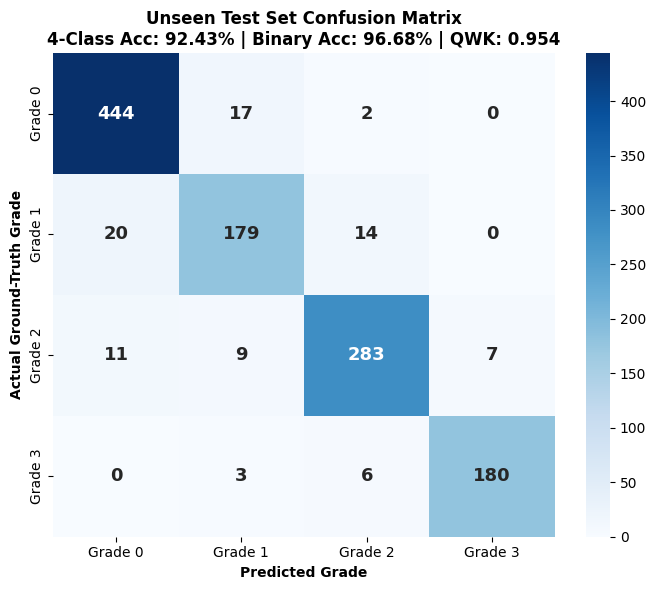

In [9]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    cohen_kappa_score,
    confusion_matrix,
    classification_report
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_CLASSES = 4

# ==========================================
# 1. CORRECT PATHS (UPDATED FROM DRIVE AUDIT)
# ==========================================
TEST_CSV_PATH = "/content/drive/MyDrive/kneeai_splits/test.csv"
DENSENET_PATH = "/content/drive/MyDrive/kneeai_splits/densenet121_best.pth"
CONVNEXT_PATH = "/content/drive/MyDrive/kneeai_splits/convnext_tiny_best.pth"

# ==========================================
# 2. DEFINE DATASET AND LOAD TEST SPLIT
# ==========================================
class KneeDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'filepath']
        label = int(self.df.loc[idx, 'label'])
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

if not os.path.exists(TEST_CSV_PATH):
    raise FileNotFoundError(f"Could not find test split CSV at {TEST_CSV_PATH}")

test_df = pd.read_csv(TEST_CSV_PATH)
unseen_dataset = KneeDataset(test_df, transform=test_transforms)
unseen_loader = DataLoader(unseen_dataset, batch_size=32, shuffle=False, num_workers=2)

print(f"Loaded {len(unseen_dataset)} test images across classes.")

# ==========================================
# 3. LOAD YOUR TRAINED ENSEMBLE MODELS
# ==========================================
def load_checkpoint(model, path, device):
    if not os.path.exists(path):
        raise FileNotFoundError(f"Could not find checkpoint at {path}")
    ckpt = torch.load(path, map_location=device)
    if isinstance(ckpt, dict) and "model_state_dict" in ckpt:
        model.load_state_dict(ckpt["model_state_dict"])
    else:
        model.load_state_dict(ckpt)
    return model.to(device).eval()

densenet = models.densenet121(weights=None)
densenet.classifier = nn.Linear(densenet.classifier.in_features, NUM_CLASSES)
densenet = load_checkpoint(densenet, DENSENET_PATH, device)

convnext = models.convnext_tiny(weights=None)
convnext.classifier[2] = nn.Linear(convnext.classifier[2].in_features, NUM_CLASSES)
convnext = load_checkpoint(convnext, CONVNEXT_PATH, device)

# ==========================================
# 4. RUN INFERENCE ON UNSEEN TEST DATA
# ==========================================
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in unseen_loader:
        images = images.to(device)

        probs_dense = F.softmax(densenet(images), dim=1)
        probs_conv  = F.softmax(convnext(images), dim=1)

        # Soft-voting ensemble average
        ensemble_probs = 0.5 * probs_dense + 0.5 * probs_conv
        preds = torch.argmax(ensemble_probs, dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

y_true = np.array(all_labels)
y_pred = np.array(all_preds)

# ==========================================
# 5. UNSEEN TEST RESULTS & CONFUSION MATRIX
# ==========================================
acc_4c  = accuracy_score(y_true, y_pred) * 100
acc_bin = accuracy_score((y_true >= 2).astype(int), (y_pred >= 2).astype(int)) * 100
qwk     = cohen_kappa_score(y_true, y_pred, weights="quadratic")
cm      = confusion_matrix(y_true, y_pred)

print("\n" + "="*55)
print(f"UNSEEN TEST RESULTS ({len(y_true)} Images)")
print("="*55)
print(f"4-Class Accuracy : {acc_4c:.2f}%")
print(f"Binary OA Acc    : {acc_bin:.2f}%  (Healthy 0-1 vs. OA 2-3)")
print(f"Quadratic Kappa  : {qwk:.3f}")
print("="*55 + "\n")

class_names = ["Grade 0", "Grade 1", "Grade 2", "Grade 3"]
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names,
            annot_kws={"size": 13, "weight": "bold"})
plt.title(f"Unseen Test Set Confusion Matrix\n4-Class Acc: {acc_4c:.2f}% | Binary Acc: {acc_bin:.2f}% | QWK: {qwk:.3f}", fontweight="bold")
plt.xlabel("Predicted Grade", fontweight="bold")
plt.ylabel("Actual Ground-Truth Grade", fontweight="bold")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/kneeai_splits/unseen_test_cm.png", dpi=300)
plt.show()

In [13]:
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
import numpy as np
from tqdm import tqdm
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score

# ==========================================
# FAST GPU EVALUATION FOR TRAINING SET
# ==========================================
fast_train_loader = DataLoader(
    train_dataset,
    batch_size=128,       # Larger batch = 4x fewer GPU calls
    shuffle=False,
    num_workers=4,        # Parallel image loading
    pin_memory=True       # Faster CPU -> GPU transfer
)

train_preds, y_tr_true = [], []
densenet.eval()
convnext.eval()

with torch.no_grad(), torch.amp.autocast("cuda"):  # Mixed precision = 2x faster on T4 GPU
    for images, labels in tqdm(fast_train_loader, desc="Evaluating Train Set"):
        images = images.to(device, non_blocking=True)

        probs = 0.5 * F.softmax(densenet(images), dim=1) + 0.5 * F.softmax(convnext(images), dim=1)
        preds = torch.argmax(probs, dim=1).cpu().numpy()

        train_preds.extend(preds)
        y_tr_true.extend(labels.numpy())

y_tr_true = np.array(y_tr_true)
y_tr_pred = np.array(train_preds)

tr_4c  = accuracy_score(y_tr_true, y_tr_pred) * 100
tr_bin = accuracy_score((y_tr_true >= 2).astype(int), (y_tr_pred >= 2).astype(int)) * 100
tr_qwk = cohen_kappa_score(y_tr_true, y_tr_pred, weights="quadratic")
tr_f1  = f1_score(y_tr_true, y_tr_pred, average="macro")

print("\n" + "=" * 55)
print(f"TRAINING SET RESULTS ({len(y_tr_true)} Images)")
print("=" * 55)
print(f"4-Class Accuracy : {tr_4c:.2f}%")
print(f"Binary OA Acc    : {tr_bin:.2f}%")
print(f"Quadratic Kappa  : {tr_qwk:.3f}")
print(f"Macro F1-Score   : {tr_f1:.3f}")
print("=" * 55)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
Evaluating Train Set:   0%|          | 0/43 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_num


TRAINING SET RESULTS (5479 Images)
4-Class Accuracy : 92.41%
Binary OA Acc    : 96.57%
Quadratic Kappa  : 0.953
Macro F1-Score   : 0.919
